<a href="https://colab.research.google.com/github/Rafeek-Data/Rafeek-Ahamed_Capstone-Project/blob/main/Rafeek_Colab_Capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Real Estate Analysis**


# **1. Data Collection**
Import all files





In [2]:
import pandas as pd

BASE = "https://raw.githubusercontent.com/Rafeek-Data/Rafeek-Ahamed_Capstone-Project/refs/heads/main/"

files = {
    "1st: 2000-2005 (approval)":    "resale-flat-prices-based-on-approval-date-2000-feb-2012_1.csv",
    "2nd: 2005-2012 (approval)":    "resale-flat-prices-based-on-approval-date-2000-feb-2012_2.csv",
    "3rd: 2012-2014 (registration)": "resale-flat-prices-based-on-registration-date-from-mar-2012-to-dec-2014.csv",
    "4th: 2015-2016 (registration)": "resale-flat-prices-based-on-registration-date-from-jan-2015-to-dec-2016.csv",
    "5th: 2017+ (registration)":    "resale-flat-prices-based-on-registration-date-from-Jan-2017-onwards.csv",
}

COLS = ["month", "town", "flat_type", "block", "street_name", "storey_range",
        "floor_area_sqm", "flat_model", "lease_commence_date", "resale_price"]

frames = []
for label, fname in files.items():
    url = BASE + fname
    df_i = pd.read_csv(url)

    # The 2nd file may have no header row: if 'month' is not a column name, reload with names
    if "month" not in df_i.columns:
        df_i = pd.read_csv(url, header=None, names=COLS)

    df_i["source"] = label
    print(f"{label:32s} rows={len(df_i):>8,}  columns={df_i.shape[1]}")
    frames.append(df_i)

# Combine all files into one DataFrame
raw = pd.concat(frames, ignore_index=True)
print("\nCombined shape:", raw.shape)
raw.head()

1st: 2000-2005 (approval)        rows= 179,999  columns=11
2nd: 2005-2012 (approval)        rows= 189,652  columns=11
3rd: 2012-2014 (registration)    rows=  52,203  columns=11
4th: 2015-2016 (registration)    rows=  37,153  columns=12
5th: 2017+ (registration)        rows= 169,584  columns=12

Combined shape: (628591, 12)


,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,resale_price,source,remaining_lease
0,2000-01,ANG MO KIO,3 ROOM,170,ANG MO KIO AVE 4,07 TO 09,69.0,Improved,1986,147000.0,1st: 2000-2005 (approval),NaN
1,2000-01,ANG MO KIO,3 ROOM,174,ANG MO KIO AVE 4,04 TO 06,61.0,Improved,1986,144000.0,1st: 2000-2005 (approval),NaN
2,2000-01,ANG MO KIO,3 ROOM,216,ANG MO KIO AVE 1,07 TO 09,73.0,New Generation,1976,159000.0,1st: 2000-2005 (approval),NaN
3,2000-01,ANG MO KIO,3 ROOM,215,ANG MO KIO AVE 1,07 TO 09,73.0,New Generation,1976,167000.0,1st: 2000-2005 (approval),NaN
4,2000-01,ANG MO KIO,3 ROOM,218,ANG MO KIO AVE 1,07 TO 09,67.0,New Generation,1976,163000.0,1st: 2000-2005 (approval),NaN


# **2. Data Understanding**

Rows, columns, types, keys and relationships

ROWS AND COLUMNS


,rows,columns,first_month,last_month
1_2000-2005,179999,10,2000-01,2005-06
2_2005-2012,189652,10,2005-06,2012-02
3_2012-2014,52203,10,2012-03,2014-12
4_2015-2016,37153,11,2015-01,2016-12
5_2017+,169584,11,2017-01,2024-01


Total rows: 628,591 | Data columns: 10 (+ remaining_lease in the 2015+ files)

Column present in each file:


,1_2000-2005,2_2005-2012,3_2012-2014,4_2015-2016,5_2017+
block,True,True,True,True,True
flat_model,True,True,True,True,True
flat_type,True,True,True,True,True
floor_area_sqm,True,True,True,True,True
lease_commence_date,True,True,True,True,True
month,True,True,True,True,True
remaining_lease,False,False,False,True,True
resale_price,True,True,True,True,True
storey_range,True,True,True,True,True
street_name,True,True,True,True,True


DATA TYPES


...

,column,type,meaning
0,month,"Date (YYYY-MM), stored as text",convert to datetime
1,town,Categorical (26),HDB town
2,flat_type,Categorical (7),"1 ROOM ... EXECUTIVE, MULTI-GENERATION"
3,block,Text,"block number, can include letters e.g. 123A"
4,street_name,Text,street address of the block
5,storey_range,Categorical band,e.g. 07 TO 09
6,floor_area_sqm,Numeric,size in square metres
7,flat_model,Categorical (21),HDB design type
8,lease_commence_date,Numeric (year),year the 99-year lease started
9,remaining_lease,Text / numeric,"only 2015+, inconsistent format"


KEYS
There is no ID column. Testing which combinations of columns could identify a sale:


,candidate key,cols,rows unique,rows duplicated,% unique
0,month+town+block+street_name,4,413183,215408,65.73%
1,+ flat_type + storey_range,6,583025,45566,92.75%
2,+ floor_area_sqm + flat_model,8,597212,31379,95.01%
3,all 10 data columns,10,626335,2256,99.64%


Unique block addresses: 9,748 (about 64 sales each)
Block addresses with more than one lease start year: 1
RELATIONSHIPS
1) The 5 files are ONE table split by time (stack them, do not join).
   Month shared by file 1 and 2: {'2005-06'}
2) Streets that appear in more than one town: 0 (0 means town > street > block is a clean hierarchy)
3) Floor area by flat type:


,count,min,50%,max
flat_type,,,,
1 ROOM,473.00,28.00,31.00,31.00
2 ROOM,"7,366.00",34.00,46.00,67.00
3 ROOM,"180,081.00",46.00,67.00,297.00
4 ROOM,"248,960.00",70.00,95.00,176.00
5 ROOM,"144,616.00",99.00,121.00,210.00
EXECUTIVE,"46,835.00",124.00,146.00,243.00
MULTI-GENERATION,260.00,132.00,164.00,179.00


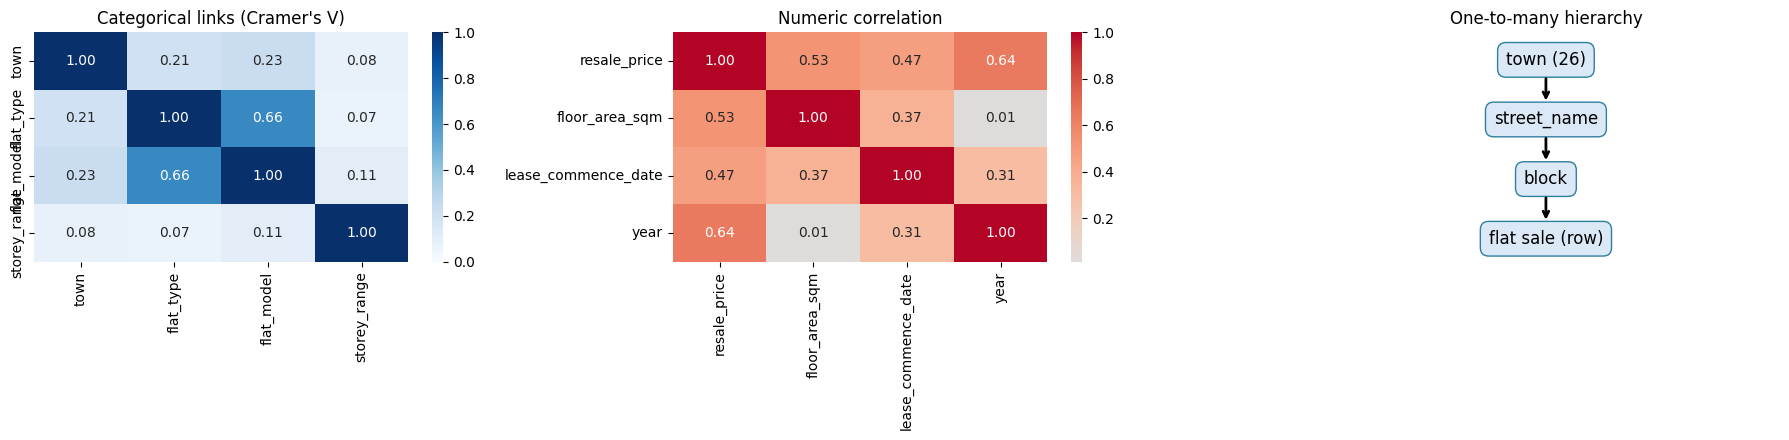

In [3]:
# ============ 2. DATA UNDERSTANDING (one cell) ============
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

pd.set_option("display.max_columns", 50)
pd.options.display.float_format = "{:,.2f}".format

# ---------- 1. LOAD ----------
BASE = "https://raw.githubusercontent.com/Rafeek-Data/Rafeek-Ahamed_Capstone-Project/refs/heads/main/"
COLS = ["month", "town", "flat_type", "block", "street_name", "storey_range",
        "floor_area_sqm", "flat_model", "lease_commence_date", "resale_price"]
FILES = {
    "1_2000-2005": "resale-flat-prices-based-on-approval-date-2000-feb-2012_1.csv",
    "2_2005-2012": "resale-flat-prices-based-on-approval-date-2000-feb-2012_2.csv",
    "3_2012-2014": "resale-flat-prices-based-on-registration-date-from-mar-2012-to-dec-2014.csv",
    "4_2015-2016": "resale-flat-prices-based-on-registration-date-from-jan-2015-to-dec-2016.csv",
    "5_2017+":     "resale-flat-prices-based-on-registration-date-from-Jan-2017-onwards.csv",
}

def load(url):
    if pd.read_csv(url, nrows=1).columns[0] == "month":       # header present
        return pd.read_csv(url)
    return pd.read_csv(url, header=None, names=COLS)           # file without header row

dfs = {k: load(BASE + f) for k, f in FILES.items()}
df = pd.concat([d.assign(source=k) for k, d in dfs.items()], ignore_index=True)

# ---------- 2. ROWS AND COLUMNS ----------
print("=" * 60, "\nROWS AND COLUMNS\n" + "=" * 60)
summary = pd.DataFrame({
    "rows":    {k: len(d) for k, d in dfs.items()},
    "columns": {k: d.shape[1] for k, d in dfs.items()},
    "first_month": {k: d["month"].min() for k, d in dfs.items()},
    "last_month":  {k: d["month"].max() for k, d in dfs.items()},
})
display(summary)
print(f"Total rows: {len(df):,} | Data columns: {len(COLS)} (+ remaining_lease in the 2015+ files)")

all_cols = sorted(set().union(*[set(d.columns) for d in dfs.values()]))
print("\nColumn present in each file:")
display(pd.DataFrame({k: [c in d.columns for c in all_cols] for k, d in dfs.items()}, index=all_cols))

# ---------- 3. TYPES ----------
print("=" * 60, "\nDATA TYPES\n" + "=" * 60)
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
    "example": df.iloc[0],
}))
display(pd.DataFrame([
    ["month", "Date (YYYY-MM), stored as text", "convert to datetime"],
    ["town", "Categorical (26)", "HDB town"],
    ["flat_type", "Categorical (7)", "1 ROOM ... EXECUTIVE, MULTI-GENERATION"],
    ["block", "Text", "block number, can include letters e.g. 123A"],
    ["street_name", "Text", "street address of the block"],
    ["storey_range", "Categorical band", "e.g. 07 TO 09"],
    ["floor_area_sqm", "Numeric", "size in square metres"],
    ["flat_model", "Categorical (21)", "HDB design type"],
    ["lease_commence_date", "Numeric (year)", "year the 99-year lease started"],
    ["remaining_lease", "Text / numeric", "only 2015+, inconsistent format"],
    ["resale_price", "Numeric (target)", "sale price in S$"],
], columns=["column", "type", "meaning"]))

# ---------- 4. KEYS ----------
print("=" * 60, "\nKEYS\n" + "=" * 60)
print("There is no ID column. Testing which combinations of columns could identify a sale:")
candidates = {
    "month+town+block+street_name": ["month", "town", "block", "street_name"],
    "+ flat_type + storey_range": ["month", "town", "block", "street_name", "flat_type", "storey_range"],
    "+ floor_area_sqm + flat_model": ["month", "town", "block", "street_name", "flat_type",
                                      "storey_range", "floor_area_sqm", "flat_model"],
    "all 10 data columns": COLS,
}
rows = []
for name, cols in candidates.items():
    dup = df.duplicated(subset=cols, keep=False).sum()
    rows.append([name, len(cols), len(df) - dup, dup, f"{1 - dup/len(df):.2%}"])
display(pd.DataFrame(rows, columns=["candidate key", "cols", "rows unique", "rows duplicated", "% unique"]))

addr = df.groupby(["town", "block", "street_name"])
print(f"Unique block addresses: {addr.ngroups:,} (about {len(df)/addr.ngroups:.0f} sales each)")
print("Block addresses with more than one lease start year:", (addr["lease_commence_date"].nunique() > 1).sum())

# ---------- 5. RELATIONSHIPS ----------
print("=" * 60, "\nRELATIONSHIPS\n" + "=" * 60)
print("1) The 5 files are ONE table split by time (stack them, do not join).")
print("   Month shared by file 1 and 2:", set(dfs["1_2000-2005"]["month"]) & set(dfs["2_2005-2012"]["month"]))
print("2) Streets that appear in more than one town:", int((df.groupby("street_name")["town"].nunique() > 1).sum()),
      "(0 means town > street > block is a clean hierarchy)")

print("3) Floor area by flat type:")
display(df.groupby("flat_type")["floor_area_sqm"].describe()[["count", "min", "50%", "max"]])

df["year"] = pd.to_datetime(df["month"], format="%Y-%m").dt.year
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    return np.sqrt(chi2_contingency(ct)[0] / (ct.values.sum() * (min(ct.shape) - 1)))
cats = ["town", "flat_type", "flat_model", "storey_range"]
cv = pd.DataFrame([[1.0 if a == b else cramers_v(df[a], df[b]) for b in cats] for a in cats], index=cats, columns=cats)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
sns.heatmap(cv, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax[0]); ax[0].set_title("Categorical links (Cramer's V)")
sns.heatmap(df[["resale_price", "floor_area_sqm", "lease_commence_date", "year"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1]); ax[1].set_title("Numeric correlation")
ax[2].axis("off")
for i, t in enumerate(["town (26)", "street_name", "block", "flat sale (row)"]):
    ax[2].text(0.5, 0.88 - i*0.26, t, ha="center", va="center", fontsize=12,
               bbox=dict(boxstyle="round,pad=0.5", fc="#dbe9f6", ec="#2f7f9e"))
    if i < 3: ax[2].annotate("", xy=(0.5, 0.88-(i+1)*0.26+0.07), xytext=(0.5, 0.88-i*0.26-0.07), arrowprops=dict(arrowstyle="->", lw=2))
ax[2].set_title("One-to-many hierarchy")
plt.tight_layout(); plt.show()

# **3. Data Cleaning**

Missing values, duplicates, formats and inconsistencies

Cell 1: Missing values

In [4]:
print("Missing values (NaN) per column:")
miss = raw.isna().sum()
display(miss[miss > 0].to_frame("missing") if miss.sum() else "No NaN in any column")

# Hidden missing values: empty strings, spaces, placeholders
text_cols = raw.select_dtypes(include=["object", "string"]).columns.drop(["source"], errors="ignore")
placeholders = ["", "NA", "N/A", "NULL", "NONE", "-", "?", "NAN"]
hidden = {c: int(raw[c].astype(str).str.strip().str.upper().isin(placeholders).sum()) for c in text_cols}
print("\nHidden/placeholder missing values:", {k: v for k, v in hidden.items() if v} or "none found")

# remaining_lease is missing only because the older files never had it
print("\nremaining_lease missing by file:")
display(raw.groupby("source")["remaining_lease"].apply(lambda s: s.isna().mean()).map("{:.0%}".format).to_frame("% missing"))
# Decision: drop remaining_lease and recompute it for ALL rows in Cell 3

Missing values (NaN) per column:


,missing
remaining_lease,421854



Hidden/placeholder missing values: {'remaining_lease': 421854}

remaining_lease missing by file:


,% missing
source,
1st: 2000-2005 (approval),100%
2nd: 2005-2012 (approval),100%
3rd: 2012-2014 (registration),100%
4th: 2015-2016 (registration),0%
5th: 2017+ (registration),0%


Cell 2: Duplicates

In [5]:
clean = raw.copy()
log = {"rows before cleaning": len(clean)}

dup_mask = clean.duplicated(subset=COLS, keep="first")
print("Exact duplicate rows (all 10 data columns):", dup_mask.sum())
print("\nDuplicates by file:")
display(clean[dup_mask].groupby("source").size().to_frame("duplicates"))
print("\nExample duplicates:")
display(clean[clean.duplicated(subset=COLS, keep=False)].sort_values(COLS).head(6)[COLS])

# Same flat sold twice in one month at the same price is very unlikely: keep the first, drop the rest
clean = clean.drop_duplicates(subset=COLS, keep="first").reset_index(drop=True)
log["duplicates removed"] = int(dup_mask.sum())
print("\nRows after removing duplicates:", len(clean))

Exact duplicate rows (all 10 data columns): 1134

Duplicates by file:


,duplicates
source,
1st: 2000-2005 (approval),305
2nd: 2005-2012 (approval),208
3rd: 2012-2014 (registration),248
4th: 2015-2016 (registration),24
5th: 2017+ (registration),349



Example duplicates:


,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,resale_price
21,2000-01,ANG MO KIO,3 ROOM,443,ANG MO KIO AVE 10,07 TO 09,67.00,New Generation,1979,"162,000.00"
22,2000-01,ANG MO KIO,3 ROOM,443,ANG MO KIO AVE 10,07 TO 09,67.00,New Generation,1979,"162,000.00"
175,2000-01,BEDOK,3 ROOM,32,CHAI CHEE AVE,13 TO 15,65.00,Improved,1974,"165,000.00"
176,2000-01,BEDOK,3 ROOM,32,CHAI CHEE AVE,13 TO 15,65.00,Improved,1974,"165,000.00"
284,2000-01,BEDOK,4 ROOM,421,BEDOK NTH RD,13 TO 15,92.00,New Generation,1979,"275,000.00"
285,2000-01,BEDOK,4 ROOM,421,BEDOK NTH RD,13 TO 15,92.00,New Generation,1979,"275,000.00"



Rows after removing duplicates: 627457


Cell 4: Inconsistencies

In [6]:
# Prepare necessary derived helper columns in 'clean' for the checks
clean["year"] = pd.to_datetime(clean["month"], errors="coerce").dt.year

def parse_remaining_lease_yrs(val):
    if pd.isna(val):
        return np.nan
    if isinstance(val, (int, float)):
        return float(val)
    parts = str(val).split()
    if 'years' in parts or 'year' in parts:
        return float(parts[0])
    try:
        return float(val)
    except:
        return np.nan

clean["remaining_lease_yrs"] = clean["remaining_lease"].apply(parse_remaining_lease_yrs)
# If remaining lease is missing, use the standard formula: 99 - (sale_year - lease_commence_date)
clean["remaining_lease_yrs"] = clean["remaining_lease_yrs"].fillna(99 - (clean["year"] - clean["lease_commence_date"].astype(float)))

# 1) Category labels: any near-duplicate spellings left?
for c in ["town", "flat_type", "flat_model"]:
    print(f"{c} ({clean[c].nunique()} values):", sorted(clean[c].unique()))

# 2) Storey bands used in each period
print("\nStorey bands per file:")
display(clean.groupby("source")["storey_range"].nunique().to_frame("distinct bands"))

# 3) Logical errors
checks = {
    "price <= 0": (clean["resale_price"].astype(float) <= 0).sum(),
    "floor area <= 0": (clean["floor_area_sqm"].astype(float) <= 0).sum(),
    "lease starts after sale year": (clean["lease_commence_date"].astype(float) > clean["year"]).sum(),
    "remaining lease outside 0-99 years": (~clean["remaining_lease_yrs"].between(0, 99)).sum(),
}
display(pd.Series(checks, name="rows").to_frame())

# 4) Floor area that does not fit the flat type (judged within each flat type)
def extreme(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - 3*i) | (s > q3 + 3*i)
clean["area_outlier"] = clean.groupby("flat_type", observed=True)["floor_area_sqm"].transform(extreme)
print("Unusual floor areas for their flat type:", clean["area_outlier"].sum())

# 5) Price outliers: judged within each year and flat type, so normal price growth is not flagged
clean["price_per_sqm"] = clean["resale_price"].astype(float) / clean["floor_area_sqm"].astype(float)
clean["price_outlier"] = clean.groupby(["year", "flat_type"], observed=True)["price_per_sqm"].transform(extreme)
print("Extreme price-per-sqm values:", clean["price_outlier"].sum(), f"({clean['price_outlier'].mean():.2%})")
display(clean[clean["price_outlier"]].sort_values("price_per_sqm", ascending=False).head(5)
        [["month", "town", "flat_type", "floor_area_sqm", "resale_price", "price_per_sqm"]])

town (26 values): ['ANG MO KIO', 'BEDOK', 'BISHAN', 'BUKIT BATOK', 'BUKIT MERAH', 'BUKIT PANJANG', 'BUKIT TIMAH', 'CENTRAL AREA', 'CHOA CHU KANG', 'CLEMENTI', 'GEYLANG', 'HOUGANG', 'JURONG EAST', 'JURONG WEST', 'KALLANG/WHAMPOA', 'MARINE PARADE', 'PASIR RIS', 'PUNGGOL', 'QUEENSTOWN', 'SEMBAWANG', 'SENGKANG', 'SERANGOON', 'TAMPINES', 'TOA PAYOH', 'WOODLANDS', 'YISHUN']
flat_type (7 values): ['1 ROOM', '2 ROOM', '3 ROOM', '4 ROOM', '5 ROOM', 'EXECUTIVE', 'MULTI-GENERATION']
flat_model (21 values): ['2-room', '3Gen', 'Adjoined flat', 'Apartment', 'DBSS', 'Improved', 'Improved-Maisonette', 'Maisonette', 'Model A', 'Model A-Maisonette', 'Model A2', 'Multi Generation', 'New Generation', 'Premium Apartment', 'Premium Apartment Loft', 'Premium Maisonette', 'Simplified', 'Standard', 'Terrace', 'Type S1', 'Type S2']

Storey bands per file:


,distinct bands
source,
1st: 2000-2005 (approval),10
2nd: 2005-2012 (approval),14
3rd: 2012-2014 (registration),22
4th: 2015-2016 (registration),17
5th: 2017+ (registration),17


,rows
price <= 0,0
floor area <= 0,0
lease starts after sale year,15
remaining lease outside 0-99 years,15


Unusual floor areas for their flat type: 2754
Extreme price-per-sqm values: 5340 (0.85%)


,month,town,flat_type,floor_area_sqm,resale_price,price_per_sqm
625520,2023-12,CENTRAL AREA,4 ROOM,93.00,"1,410,888.00","15,170.84"
616895,2023-08,CENTRAL AREA,4 ROOM,94.00,"1,410,000.00","15,000.00"
619198,2023-09,CENTRAL AREA,4 ROOM,94.00,"1,393,939.00","14,829.14"
608478,2023-04,CENTRAL AREA,4 ROOM,95.00,"1,400,000.00","14,736.84"
595407,2022-10,CENTRAL AREA,4 ROOM,93.00,"1,370,000.00","14,731.18"


Cell 6: Save the clean file

In [7]:
clean.to_csv("hdb_resale_clean.csv", index=False)
from google.colab import files
files.download("hdb_resale_clean.csv")      # or save to your Drive instead

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **4. Exploratory Data Analysis**

Trends, patterns, outliers and relationships

Cell 1: Setup and summary

In [8]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import pandas as pd
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)
money = mtick.StrMethodFormatter("{x:,.0f}")
order = ["1 ROOM", "2 ROOM", "3 ROOM", "4 ROOM", "5 ROOM", "EXECUTIVE", "MULTI-GENERATION"]

# Convert month to datetime to safely call .date()
min_month = pd.to_datetime(clean["month"]).min().date()
max_month = pd.to_datetime(clean["month"]).max().date()

print("Rows:", f"{len(clean):,}", "| period:", min_month, "to", max_month)

# Safely display summary statistics of numerical properties
numerical_cols = ["resale_price", "floor_area_sqm", "price_per_sqm", "remaining_lease_yrs"]
available_cols = [c for c in numerical_cols if c in clean.columns]
display(clean[available_cols].astype(float).describe().T)

Rows: 627,457 | period: 2000-01-01 to 2024-01-01


,count,mean,std,min,25%,50%,75%,max
resale_price,"627,457.00","362,084.88","164,351.58","28,000.00","240,000.00","338,000.00","450,000.00","1,500,000.00"
floor_area_sqm,"627,457.00",96.78,25.05,28.00,74.00,96.00,113.00,297.00
price_per_sqm,"627,457.00","3,757.30","1,473.32",662.34,"2,537.31","3,553.72","4,619.57","15,170.84"
remaining_lease_yrs,"627,457.00",78.73,11.49,42.00,71.00,79.00,89.00,101.00


Cell 2: Trends

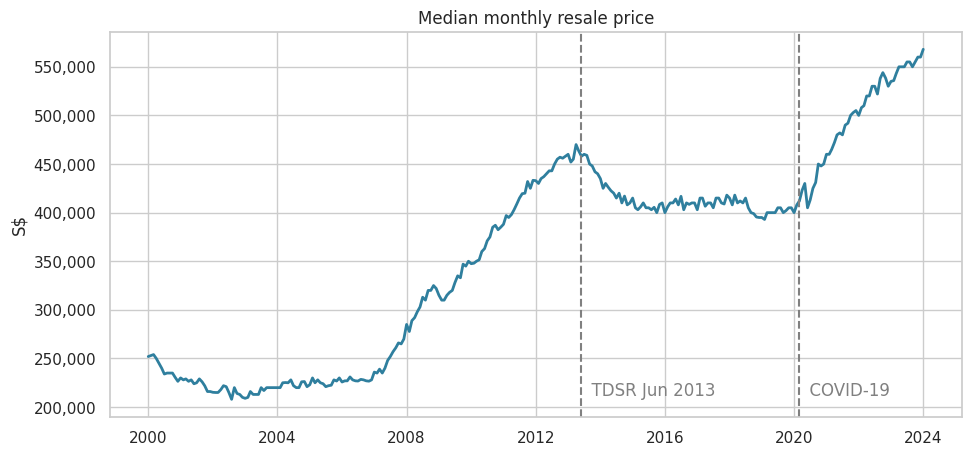

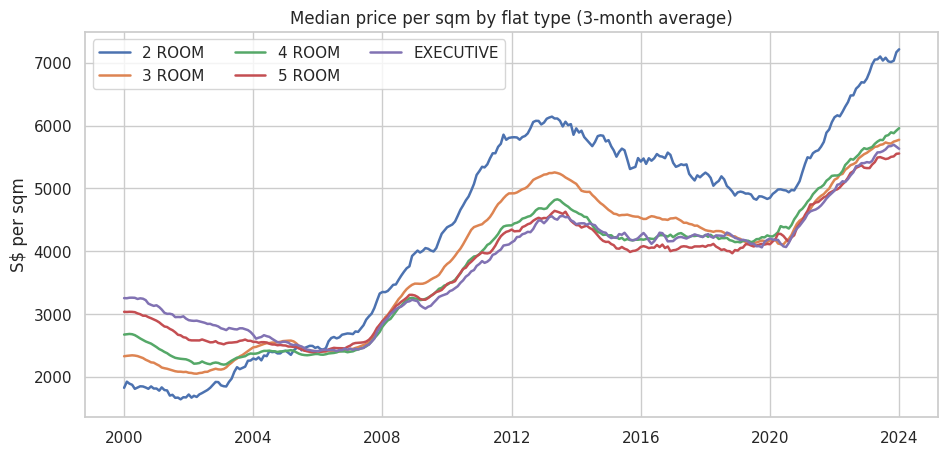

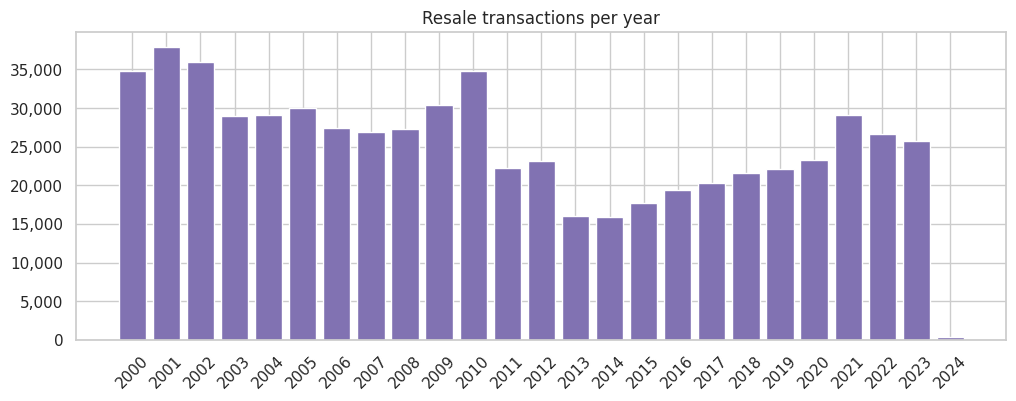

year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
YoY % change,NaN,-5.90,-4.20,0.70,3.10,0.50,1.30,9.60,22.00,8.20,10.90,12.00,8.50,2.20,-7.70,-3.60,1.20,0.00,-0.50,-2.00,6.20,13.60,8.70,4.80,3.30


In [9]:
# 2a) Median price over time
monthly = clean.groupby("month")["resale_price"].median()
# Convert index to Datetime objects to allow proper temporal coordinate mapping for pd.Timestamp lines
monthly.index = pd.to_datetime(monthly.index)

fig, ax = plt.subplots()
ax.plot(monthly.index, monthly.values, lw=2, color="#2f7f9e")
ax.set(title="Median monthly resale price", ylabel="S$")
ax.yaxis.set_major_formatter(money)
ax.axvline(pd.Timestamp("2013-06-01"), color="grey", ls="--"); ax.text(pd.Timestamp("2013-06-01"), monthly.min(), "  TDSR Jun 2013", color="grey", va="bottom")
ax.axvline(pd.Timestamp("2020-03-01"), color="grey", ls="--"); ax.text(pd.Timestamp("2020-03-01"), monthly.min(), "  COVID-19", color="grey", va="bottom")
plt.show()

# 2b) Price per sqm by flat type (removes the size effect)
t = clean.groupby(["month", "flat_type"], observed=True)["price_per_sqm"].median().unstack()
t.index = pd.to_datetime(t.index)
t = t.drop(columns=["MULTI-GENERATION", "1 ROOM"], errors="ignore").rolling(3, min_periods=1).mean()
fig, ax = plt.subplots()
for c in t.columns:
    ax.plot(t.index, t[c], label=c, lw=1.8)
ax.set(title="Median price per sqm by flat type (3-month average)", ylabel="S$ per sqm"); ax.legend(ncol=3)
plt.show()

# 2c) Number of sales per year (2024 has January only)
vol = clean.groupby("year").size()
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(vol.index.astype(str), vol.values, color="#8172b2")
ax.set(title="Resale transactions per year"); ax.yaxis.set_major_formatter(money); ax.tick_params(axis="x", rotation=45)
plt.show()

# 2d) Year-on-year change in the median price
yoy = clean.groupby("year")["resale_price"].median().pct_change() * 100
display(yoy.round(1).to_frame("YoY % change").T)

Cell 3: Patterns

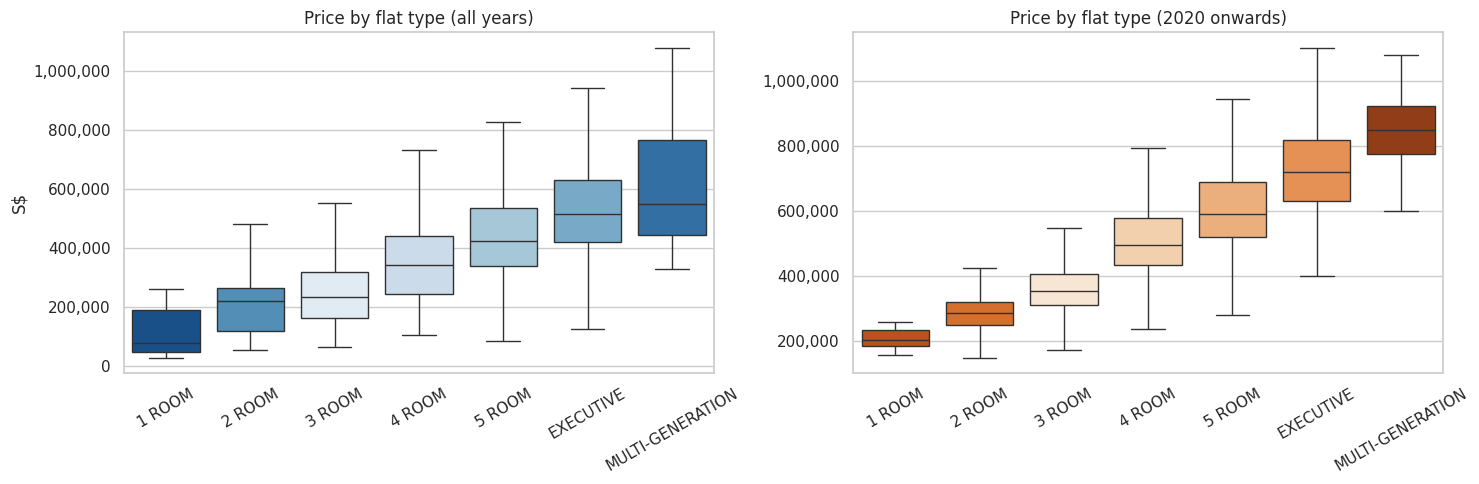

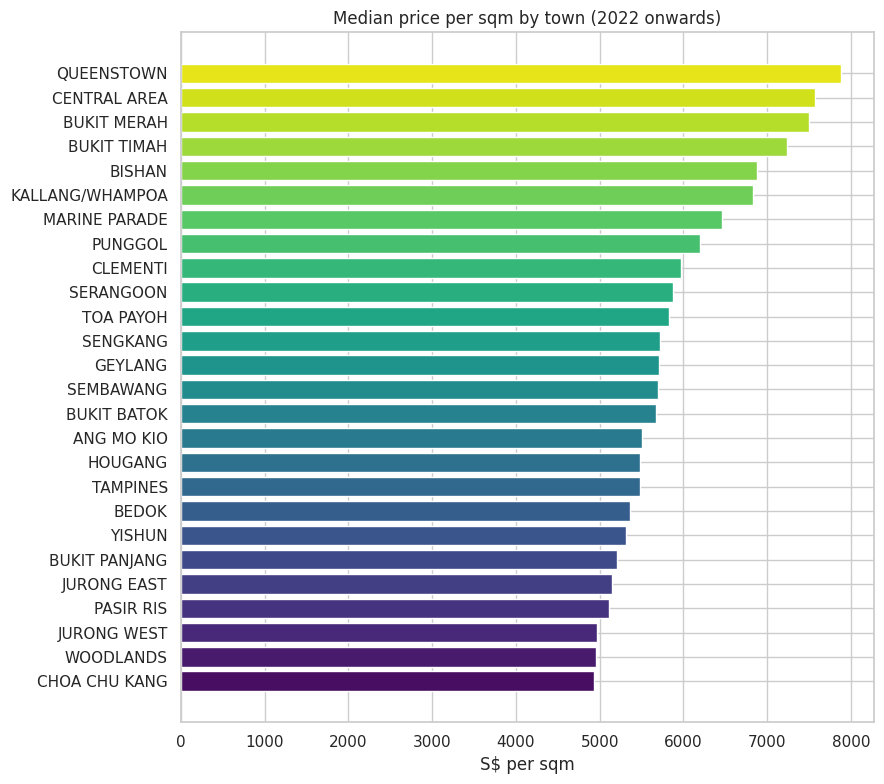

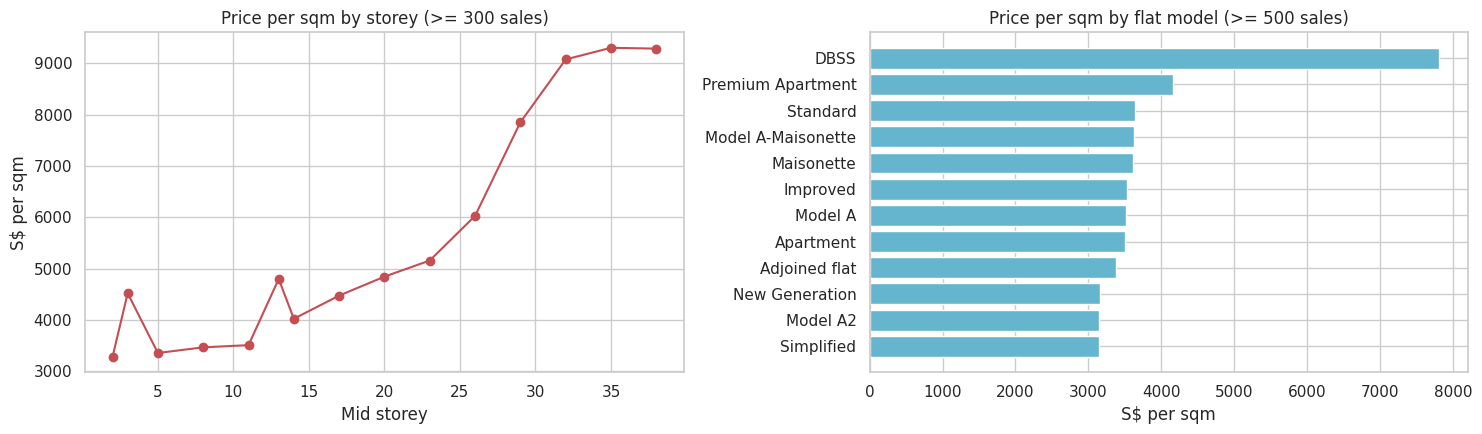

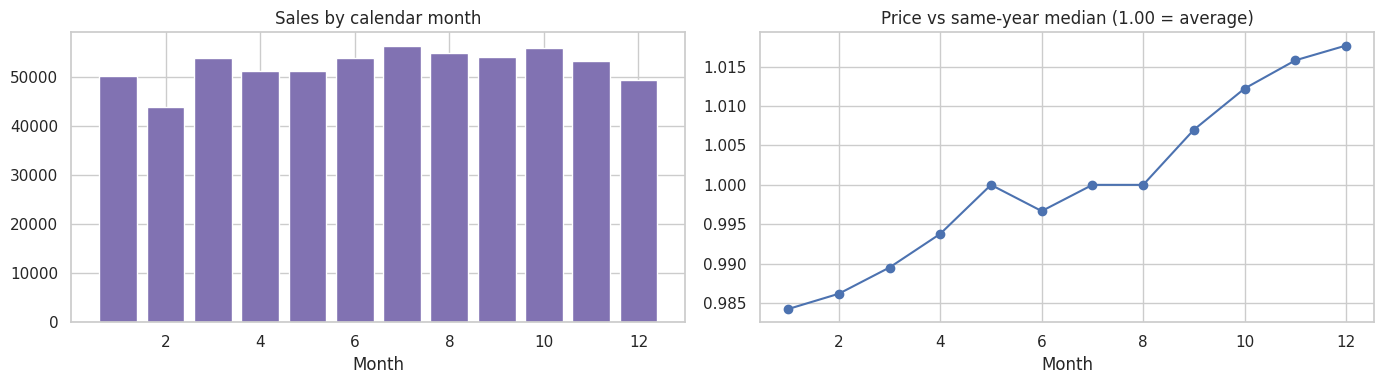

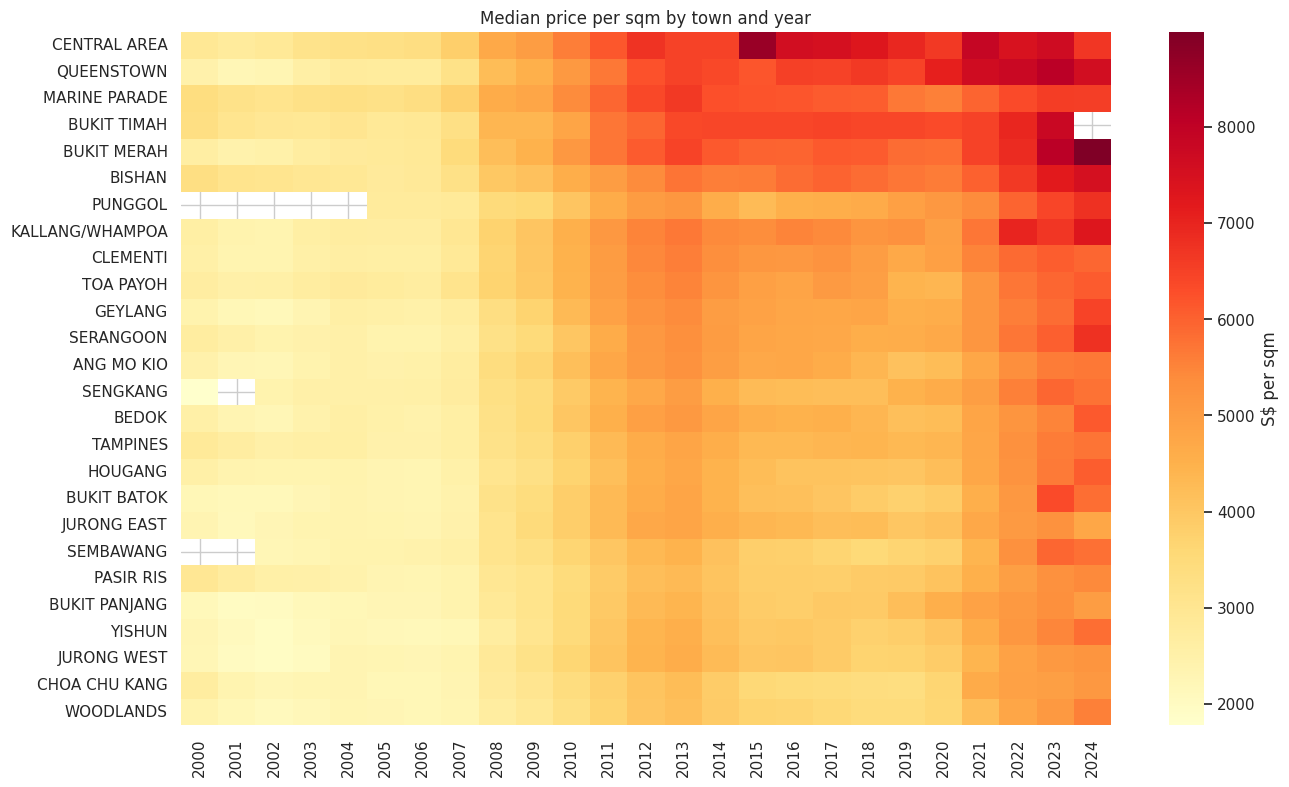

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Helper function to parse 'storey_range' and get the middle value
def parse_storey_mid(val):
    if pd.isna(val):
        return np.nan
    parts = str(val).upper().split(' TO ')
    if len(parts) == 2:
        try:
            return (float(parts[0]) + float(parts[1])) / 2.0
        except:
            return np.nan
    return np.nan

# Parse storey_mid dynamically since it was missing from the dataframe
if "storey_mid" not in clean.columns and "storey_range" in clean.columns:
    clean["storey_mid"] = clean["storey_range"].apply(parse_storey_mid)

# 3a) Price by flat type
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=clean, x="flat_type", y="resale_price", order=order, showfliers=False, ax=ax[0], palette="Blues", hue="flat_type", legend=False)
ax[0].set(title="Price by flat type (all years)", xlabel="", ylabel="S$"); ax[0].tick_params(axis="x", rotation=30); ax[0].yaxis.set_major_formatter(money)
sns.boxplot(data=clean[clean["year"] >= 2020], x="flat_type", y="resale_price", order=order, showfliers=False, ax=ax[1], palette="Oranges", hue="flat_type", legend=False)
ax[1].set(title="Price by flat type (2020 onwards)", xlabel="", ylabel=""); ax[1].tick_params(axis="x", rotation=30); ax[1].yaxis.set_major_formatter(money)
plt.tight_layout(); plt.show()

# 3b) Town ranking (recent years)
town = clean[clean["year"] >= 2022].groupby("town", observed=True)["price_per_sqm"].median().sort_values()
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(town.index.astype(str), town.values, color=sns.color_palette("viridis", len(town)))
ax.set(title="Median price per sqm by town (2022 onwards)", xlabel="S$ per sqm")
plt.tight_layout(); plt.show()

# 3c) Storey and flat model
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sm = clean.groupby("storey_mid")["price_per_sqm"].agg(["median", "size"]); sm = sm[sm["size"] >= 300]
ax[0].plot(sm.index, sm["median"], marker="o", color="#c44e52"); ax[0].set(title="Price per sqm by storey (>= 300 sales)", xlabel="Mid storey", ylabel="S$ per sqm")
mm = clean.groupby("flat_model", observed=True)["price_per_sqm"].agg(["median", "size"]); mm = mm[mm["size"] >= 500].sort_values("median")
ax[1].barh(mm.index.astype(str), mm["median"], color="#64b5cd"); ax[1].set(title="Price per sqm by flat model (>= 500 sales)", xlabel="S$ per sqm")
plt.tight_layout(); plt.show()

# 3d) Seasonality: convert 'month' to datetime before calling the .dt accessor
clean["month_dt"] = pd.to_datetime(clean["month"], errors="coerce")
clean["cal_month"] = clean["month_dt"].dt.month
detr = clean.assign(rel=clean["resale_price"].astype(float) / clean.groupby(["year", "flat_type"], observed=True)["resale_price"].transform("median"))
seas = detr[detr["year"] < 2024].groupby("cal_month").agg(price_index=("rel", "median"), sales=("rel", "size"))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(seas.index, seas["sales"], color="#8172b2"); ax[0].set(title="Sales by calendar month", xlabel="Month")
ax[1].plot(seas.index, seas["price_index"], marker="o"); ax[1].set(title="Price vs same-year median (1.00 = average)", xlabel="Month")
plt.tight_layout(); plt.show()

# 3e) Town x year heatmap
hm = clean.pivot_table(index="town", columns="year", values="price_per_sqm", aggfunc="median", observed=True)
hm = hm.loc[hm.mean(axis=1).sort_values(ascending=False).index]
plt.figure(figsize=(15, 9)); sns.heatmap(hm, cmap="YlOrRd", cbar_kws={"label": "S$ per sqm"})
plt.title("Median price per sqm by town and year"); plt.xlabel(""); plt.ylabel(""); plt.show()

Cell 4: Outliers

Flagged price outliers: 5340 | unusual areas: 2754


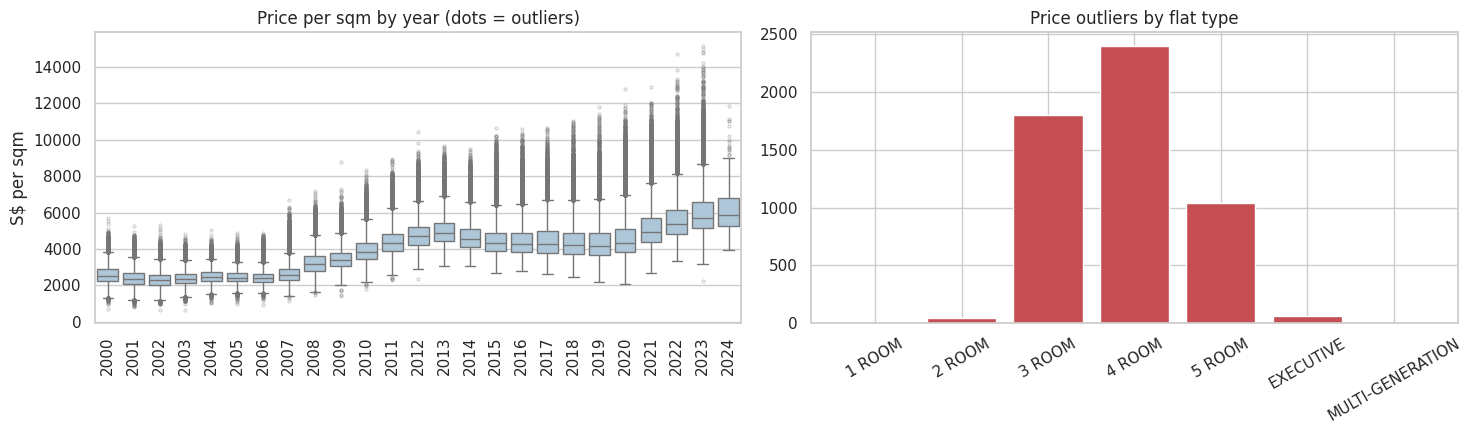

Where are the outliers? Top towns:


,outliers
town,
BUKIT MERAH,1578
QUEENSTOWN,1353
CENTRAL AREA,856
KALLANG/WHAMPOA,510
TOA PAYOH,450
CLEMENTI,246


Highest-priced sales:


,month,town,flat_type,flat_model,floor_area_sqm,storey_range,resale_price
612700,2023-06,BUKIT MERAH,4 ROOM,Adjoined flat,176.00,04 TO 06,"1,500,000.00"
616902,2023-08,CENTRAL AREA,5 ROOM,Type S2,107.00,28 TO 30,"1,480,000.00"
618368,2023-08,TOA PAYOH,5 ROOM,DBSS,114.00,40 TO 42,"1,460,000.00"
623349,2023-11,BUKIT MERAH,5 ROOM,Improved,113.00,31 TO 33,"1,460,000.00"
618936,2023-09,BISHAN,EXECUTIVE,Maisonette,172.00,19 TO 21,"1,450,000.00"


Lowest price per sqm:


,month,town,flat_type,floor_area_sqm,resale_price,price_per_sqm
112332,2003-02,JURONG EAST,5 ROOM,154.00,"102,000.00",662.34
96028,2002-08,JURONG WEST,5 ROOM,127.00,"84,500.00",665.35
14639,2000-06,JURONG WEST,5 ROOM,130.00,"93,000.00",715.38
60791,2001-09,CLEMENTI,EXECUTIVE,150.00,"125,000.00",833.33
44178,2001-04,BUKIT BATOK,5 ROOM,128.00,"109,000.00",851.56


In [11]:
print("Flagged price outliers:", clean["price_outlier"].sum(), "| unusual areas:", clean["area_outlier"].sum())

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=clean, x="year", y="price_per_sqm", showfliers=True, flierprops=dict(markersize=2, alpha=.3), ax=ax[0], color="#a6c8e0")
ax[0].set(title="Price per sqm by year (dots = outliers)", xlabel="", ylabel="S$ per sqm"); ax[0].tick_params(axis="x", rotation=90)
oc = clean[clean["price_outlier"]].groupby("flat_type", observed=True).size().reindex(order).fillna(0)
ax[1].bar(oc.index, oc.values, color="#c44e52"); ax[1].set(title="Price outliers by flat type"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

print("Where are the outliers? Top towns:")
display(clean[clean["price_outlier"]].groupby("town", observed=True).size().sort_values(ascending=False).head(6).to_frame("outliers"))
print("Highest-priced sales:")
display(clean.nlargest(5, "resale_price")[["month", "town", "flat_type", "flat_model", "floor_area_sqm", "storey_range", "resale_price"]])
print("Lowest price per sqm:")
display(clean.nsmallest(5, "price_per_sqm")[["month", "town", "flat_type", "floor_area_sqm", "resale_price", "price_per_sqm"]])

Cell 5: Relationships

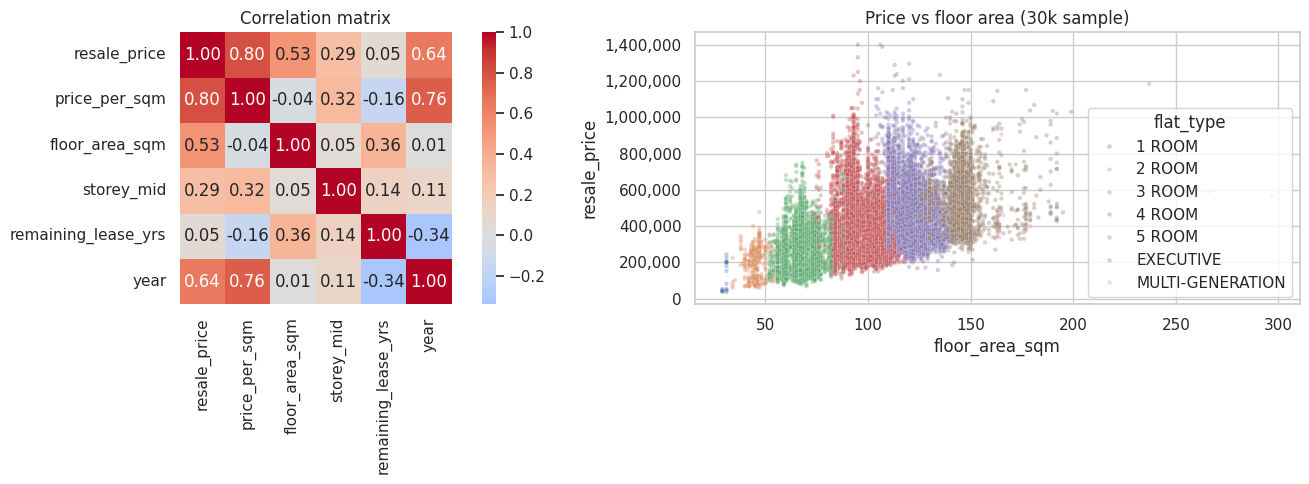

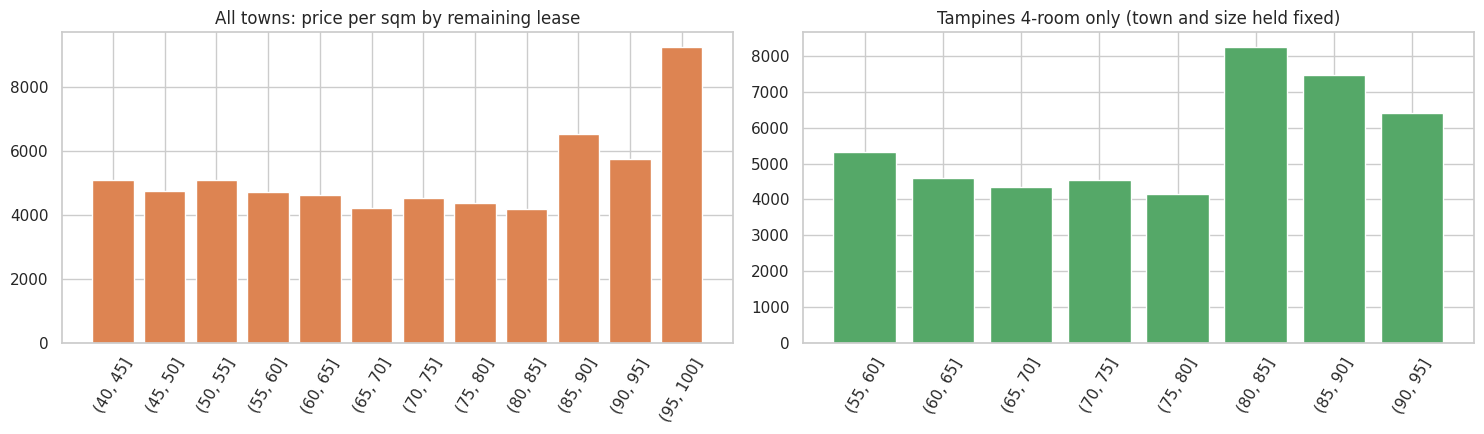

In [12]:
num = clean[["resale_price", "price_per_sqm", "floor_area_sqm", "storey_mid", "remaining_lease_yrs", "year"]]
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax[0]); ax[0].set_title("Correlation matrix")
sns.scatterplot(data=clean.sample(30000, random_state=1), x="floor_area_sqm", y="resale_price", hue="flat_type", hue_order=order, alpha=.35, s=10, ax=ax[1])
ax[1].set(title="Price vs floor area (30k sample)"); ax[1].yaxis.set_major_formatter(money)
plt.tight_layout(); plt.show()

# Remaining lease vs price per sqm (2017 onwards), then inside one town and flat type to remove the location effect
r = clean[clean["year"] >= 2017].copy()
r["lease_band"] = pd.cut(r["remaining_lease_yrs"], bins=range(40, 101, 5))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
a = r.groupby("lease_band", observed=True)["price_per_sqm"].median()
ax[0].bar(a.index.astype(str), a.values, color="#dd8452"); ax[0].set(title="All towns: price per sqm by remaining lease"); ax[0].tick_params(axis="x", rotation=60)
one = r[(r["town"] == "TAMPINES") & (r["flat_type"] == "4 ROOM")]
b = one.groupby("lease_band", observed=True)["price_per_sqm"].median().dropna()
ax[1].bar(b.index.astype(str), b.values, color="#55a868"); ax[1].set(title="Tampines 4-room only (town and size held fixed)"); ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

Cell 6: Key figures to quote

In [13]:
by_year = clean.groupby("year")["resale_price"].median()
print(f"Median price {by_year.index[0]}: S${by_year.iloc[0]:,.0f} -> {by_year.index[-1]}: S${by_year.iloc[-1]:,.0f} ({by_year.iloc[-1]/by_year.iloc[0]-1:+.0%})")
print("Peak year before 2020:", by_year[by_year.index < 2020].idxmax(), f"(S${by_year[by_year.index < 2020].max():,.0f})")
print("Busiest year:", vol.idxmax(), "| quietest full year:", vol[vol.index < 2024].idxmin())
print("Dearest towns (price/sqm, 2022+):", list(town.index[-3:][::-1]), "| cheapest:", list(town.index[:3]))
print("Correlation price vs area:", round(num.corr().loc["resale_price", "floor_area_sqm"], 2),
      "| price vs year:", round(num.corr().loc["resale_price", "year"], 2))

Median price 2000: S$239,000 -> 2024: S$568,000 (+138%)
Peak year before 2020: 2013 (S$455,000)
Busiest year: 2001 | quietest full year: 2014
Dearest towns (price/sqm, 2022+): ['QUEENSTOWN', 'CENTRAL AREA', 'BUKIT MERAH'] | cheapest: ['CHOA CHU KANG', 'WOODLANDS', 'JURONG WEST']
Correlation price vs area: 0.53 | price vs year: 0.64


# **5. Visualization**

Bar charts, histograms, line charts and heatmaps

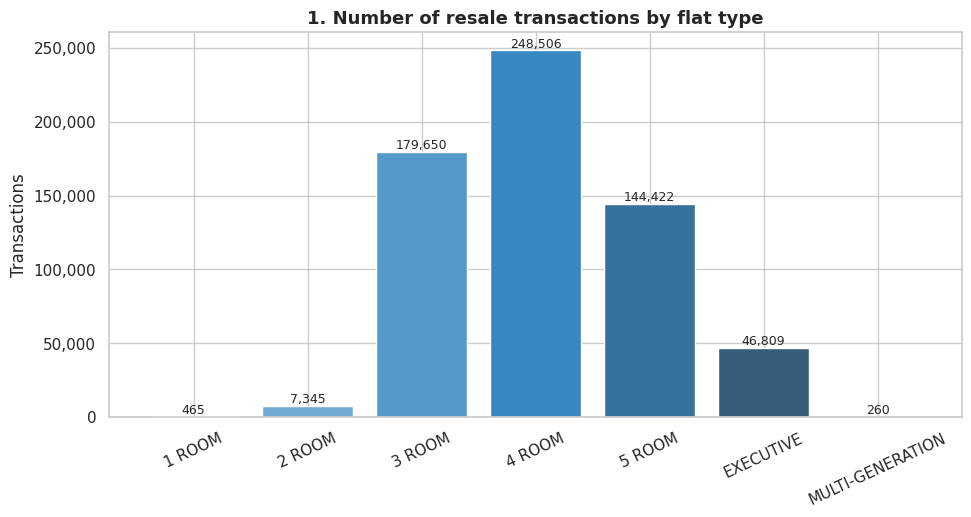

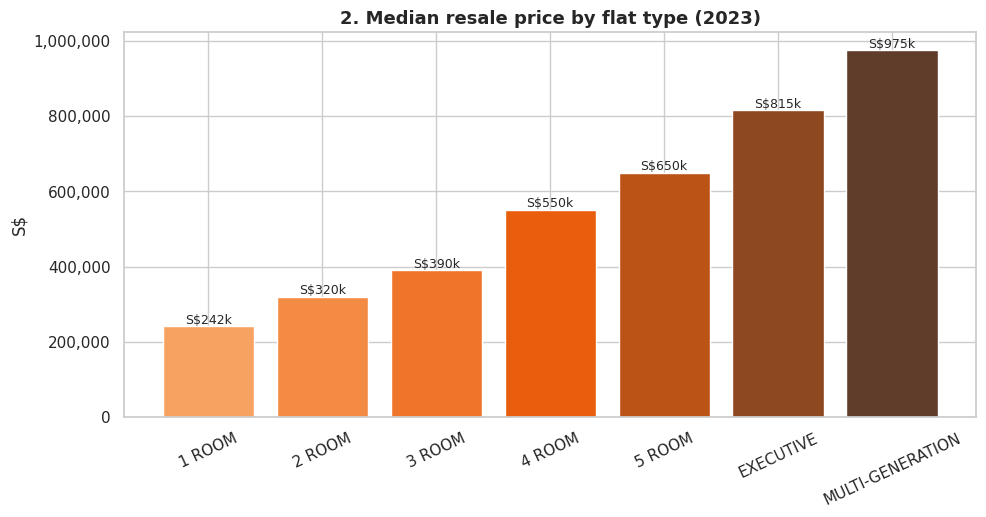

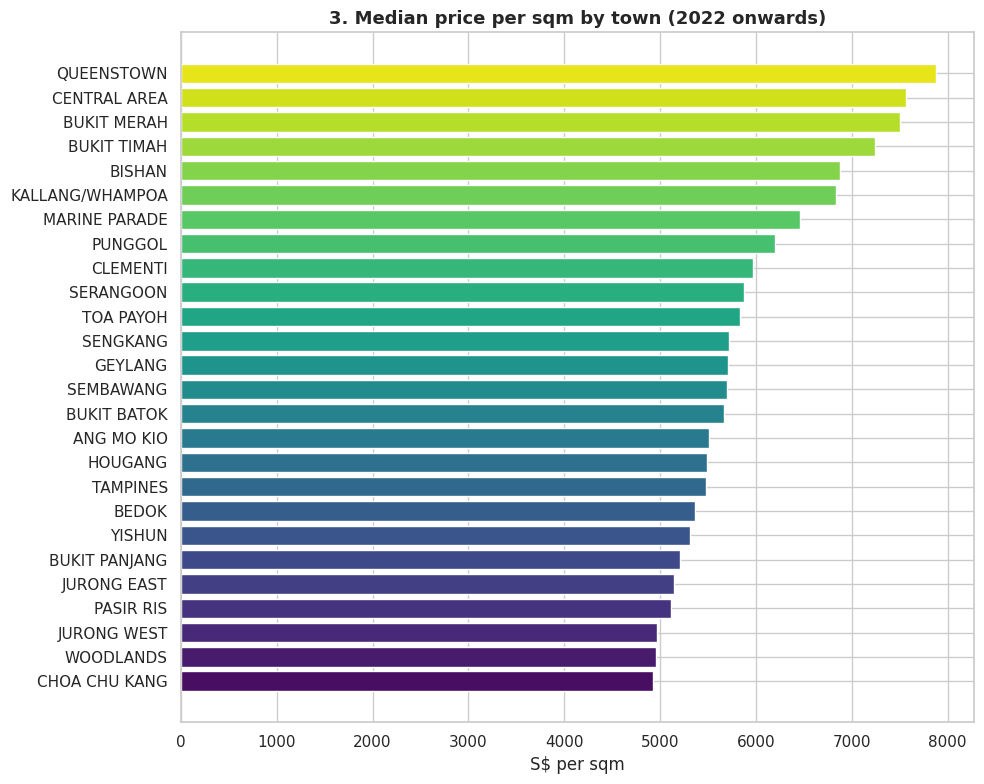

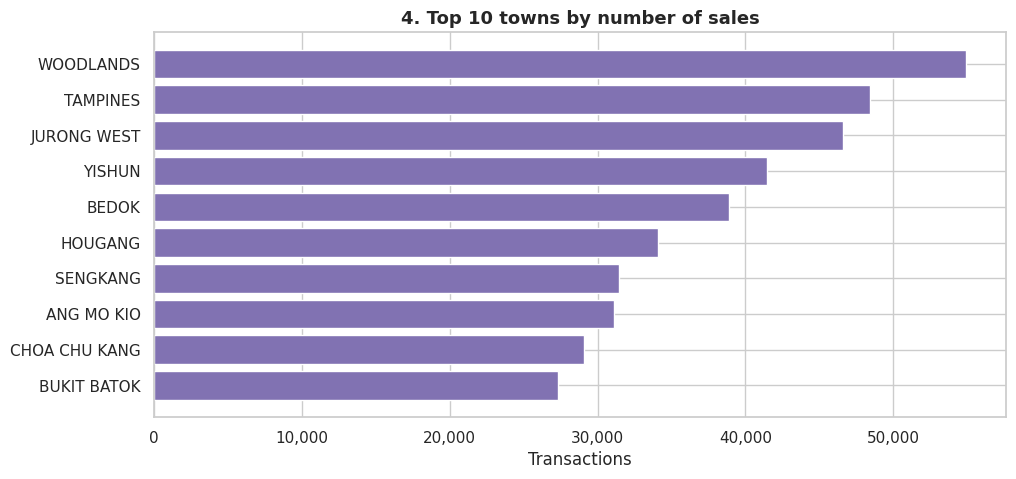

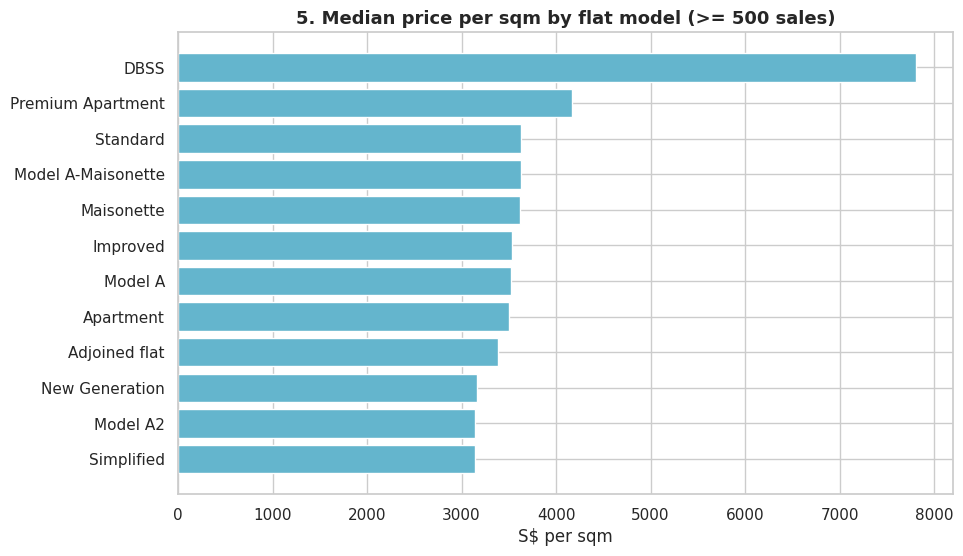

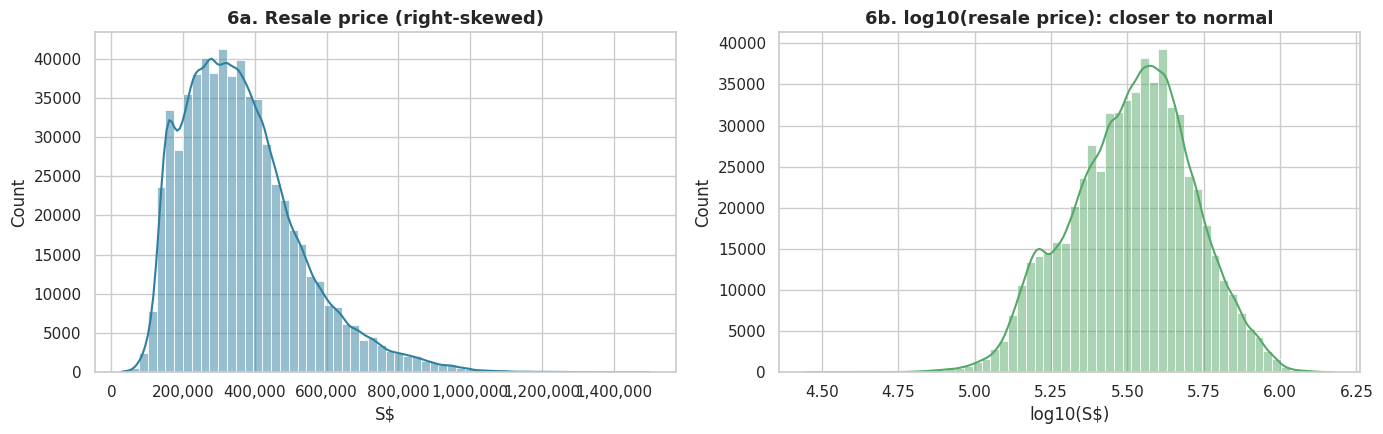

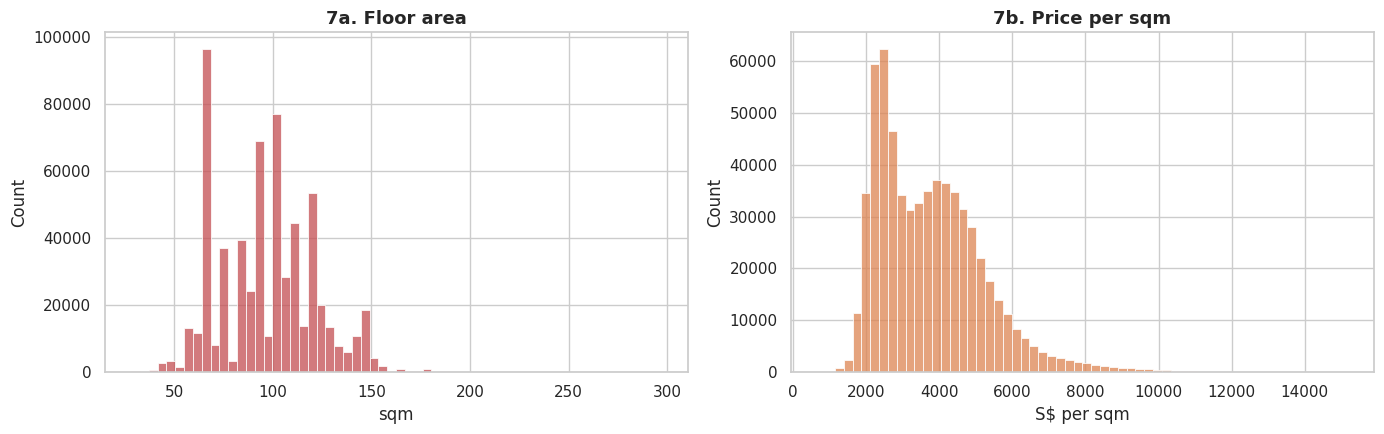

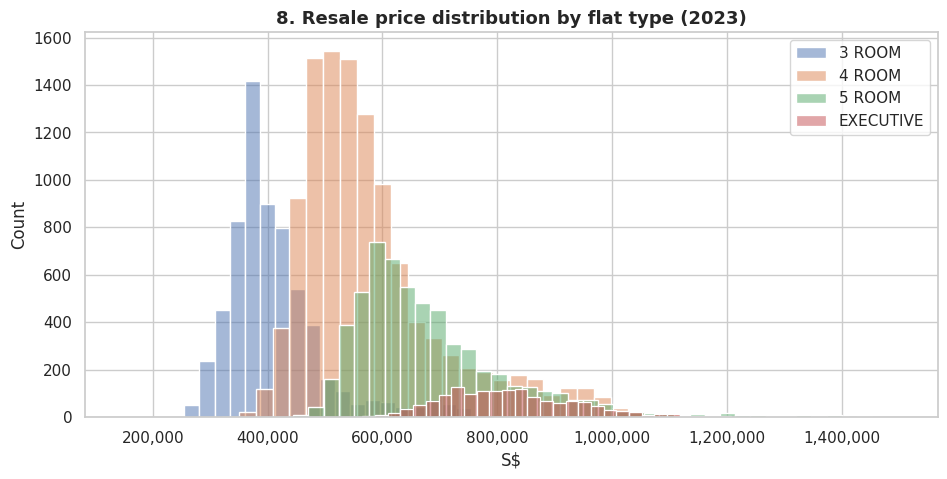

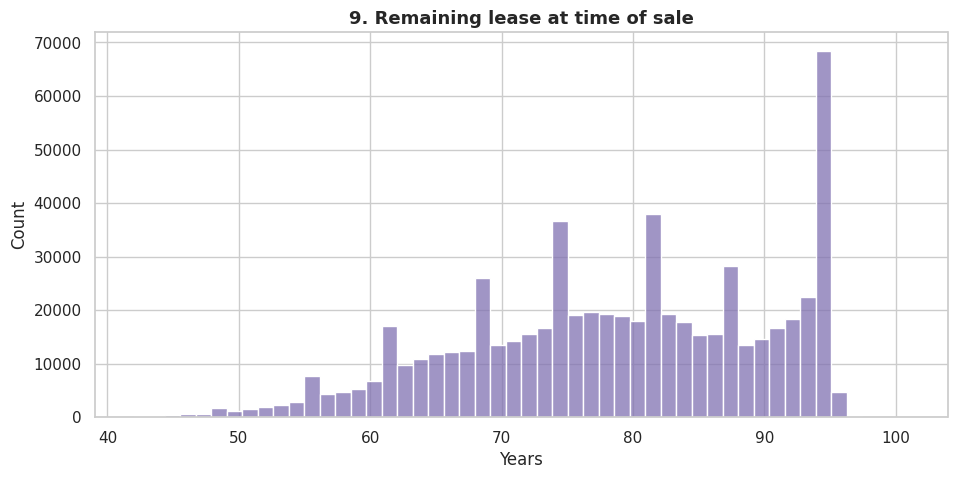

ConversionError: Failed to convert value(s) to axis units: Timestamp('2013-06-01 00:00:00')

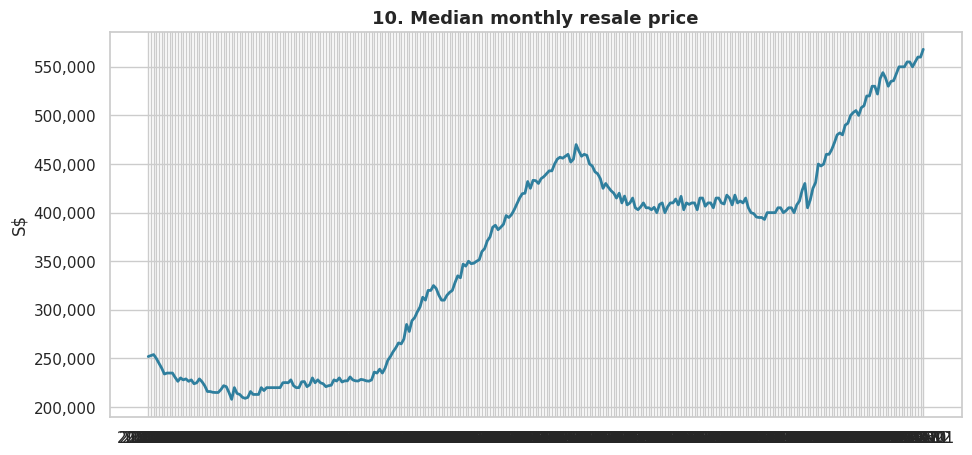

In [14]:
# ==== 5. VISUALIZATION: bar charts, histograms, line charts, heatmaps (one cell) ====
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# ---- 0) Data: use `clean` from the previous section; otherwise load and tidy it here ----
if "clean" not in globals():
    BASE = "https://raw.githubusercontent.com/Rafeek-Data/Rafeek-Ahamed_Capstone-Project/refs/heads/main/"
    COLS = ["month", "town", "flat_type", "block", "street_name", "storey_range",
            "floor_area_sqm", "flat_model", "lease_commence_date", "resale_price"]
    FILES = ["resale-flat-prices-based-on-approval-date-2000-feb-2012_1.csv",
             "resale-flat-prices-based-on-approval-date-2000-feb-2012_2.csv",
             "resale-flat-prices-based-on-registration-date-from-mar-2012-to-dec-2014.csv",
             "resale-flat-prices-based-on-registration-date-from-jan-2015-to-dec-2016.csv",
             "resale-flat-prices-based-on-registration-date-from-Jan-2017-onwards.csv"]
    def load(url):
        head = pd.read_csv(url, nrows=1)
        d = pd.read_csv(url) if head.columns[0] == "month" else pd.read_csv(url, header=None, names=COLS)
        return d[COLS]
    clean = pd.concat([load(BASE + f) for f in FILES], ignore_index=True).drop_duplicates()
    clean["month"] = pd.to_datetime(clean["month"], format="%Y-%m")
    clean["year"] = clean["month"].dt.year
    for c in ["town", "flat_type", "flat_model"]:
        clean[c] = clean[c].astype(str).str.strip().str.upper()
    clean["flat_type"] = clean["flat_type"].str.replace("MULTI GENERATION", "MULTI-GENERATION")
    st = clean["storey_range"].str.extract(r"(\d+)\s*TO\s*(\d+)").astype(float)
    clean["storey_mid"] = (st[0] + st[1]) / 2
    clean["price_per_sqm"] = clean["resale_price"] / clean["floor_area_sqm"]
    clean["remaining_lease_yrs"] = 99 - (clean["year"] - clean["lease_commence_date"])
    clean = clean[clean["remaining_lease_yrs"].between(0, 99)].reset_index(drop=True)

# ---- Style and helpers ----
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 5), "axes.titleweight": "bold", "axes.titlesize": 13})
money = mtick.StrMethodFormatter("{x:,.0f}")
order = ["1 ROOM", "2 ROOM", "3 ROOM", "4 ROOM", "5 ROOM", "EXECUTIVE", "MULTI-GENERATION"]
recent = clean[clean["year"] >= 2022]           # recent years for location comparisons
full_years = clean[clean["year"] < 2024]        # 2024 holds January only

# =========================== BAR CHARTS ===========================
# 1) Number of sales by flat type
cnt = clean["flat_type"].value_counts().reindex(order)
fig, ax = plt.subplots()
ax.bar(cnt.index, cnt.values, color=sns.color_palette("Blues_d", len(cnt)))
for i, v in enumerate(cnt.values): ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set(title="1. Number of resale transactions by flat type", ylabel="Transactions"); ax.yaxis.set_major_formatter(money)
ax.tick_params(axis="x", rotation=25); plt.show()

# 2) Median price by flat type, 2023
p23 = clean[clean["year"] == 2023].groupby("flat_type")["resale_price"].median().reindex(order)
fig, ax = plt.subplots()
ax.bar(p23.index, p23.values, color=sns.color_palette("Oranges_d", len(p23)))
for i, v in enumerate(p23.values): ax.text(i, v, f"S${v/1000:,.0f}k", ha="center", va="bottom", fontsize=9)
ax.set(title="2. Median resale price by flat type (2023)", ylabel="S$"); ax.yaxis.set_major_formatter(money)
ax.tick_params(axis="x", rotation=25); plt.show()

# 3) Towns: most and least expensive per sqm (2022 onwards)
tw = recent.groupby("town")["price_per_sqm"].median().sort_values()
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(tw.index, tw.values, color=sns.color_palette("viridis", len(tw)))
ax.set(title="3. Median price per sqm by town (2022 onwards)", xlabel="S$ per sqm"); plt.tight_layout(); plt.show()

# 4) Top 10 towns by number of sales
top = clean["town"].value_counts().head(10).sort_values()
fig, ax = plt.subplots()
ax.barh(top.index, top.values, color="#8172b2")
ax.set(title="4. Top 10 towns by number of sales", xlabel="Transactions"); ax.xaxis.set_major_formatter(money); plt.show()

# 5) Flat model: price per sqm (models with at least 500 sales)
fm = clean.groupby("flat_model")["price_per_sqm"].agg(["median", "size"]); fm = fm[fm["size"] >= 500].sort_values("median")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(fm.index, fm["median"], color="#64b5cd")
ax.set(title="5. Median price per sqm by flat model (>= 500 sales)", xlabel="S$ per sqm"); plt.show()

# =========================== HISTOGRAMS ===========================
# 6) Distribution of price: raw and log
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(clean["resale_price"], bins=60, kde=True, color="#2f7f9e", ax=ax[0])
ax[0].set(title="6a. Resale price (right-skewed)", xlabel="S$"); ax[0].xaxis.set_major_formatter(money)
sns.histplot(np.log10(clean["resale_price"]), bins=60, kde=True, color="#55a868", ax=ax[1])
ax[1].set(title="6b. log10(resale price): closer to normal", xlabel="log10(S$)")
plt.tight_layout(); plt.show()

# 7) Floor area and price per sqm
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(clean["floor_area_sqm"], bins=60, color="#c44e52", ax=ax[0]); ax[0].set(title="7a. Floor area", xlabel="sqm")
sns.histplot(clean["price_per_sqm"], bins=60, color="#dd8452", ax=ax[1]); ax[1].set(title="7b. Price per sqm", xlabel="S$ per sqm")
plt.tight_layout(); plt.show()

# 8) Price distribution by flat type (2023), overlaid
fig, ax = plt.subplots()
for ft in ["3 ROOM", "4 ROOM", "5 ROOM", "EXECUTIVE"]:
    sns.histplot(clean[(clean["year"] == 2023) & (clean["flat_type"] == ft)]["resale_price"], bins=40, alpha=.5, label=ft, ax=ax)
ax.set(title="8. Resale price distribution by flat type (2023)", xlabel="S$"); ax.xaxis.set_major_formatter(money); ax.legend()
plt.show()

# 9) Remaining lease at time of sale
fig, ax = plt.subplots()
sns.histplot(clean["remaining_lease_yrs"], bins=50, color="#8172b2", ax=ax)
ax.set(title="9. Remaining lease at time of sale", xlabel="Years"); plt.show()

# =========================== LINE CHARTS ===========================
# 10) Median price over time with events
m = clean.groupby("month")["resale_price"].median()
fig, ax = plt.subplots()
ax.plot(m.index, m.values, lw=2, color="#2f7f9e")
ax.set(title="10. Median monthly resale price", ylabel="S$"); ax.yaxis.set_major_formatter(money)
for d, lbl in [("2013-06-01", "TDSR Jun 2013"), ("2020-03-01", "COVID-19")]:
    ax.axvline(pd.Timestamp(d), color="grey", ls="--"); ax.text(pd.Timestamp(d), m.min(), " " + lbl, color="grey")
plt.show()

# 11) Price per sqm by flat type (3-month average)
t = clean.groupby(["month", "flat_type"])["price_per_sqm"].median().unstack()
t = t[["2 ROOM", "3 ROOM", "4 ROOM", "5 ROOM", "EXECUTIVE"]].rolling(3, min_periods=1).mean()
fig, ax = plt.subplots()
for c in t.columns: ax.plot(t.index, t[c], lw=1.8, label=c)
ax.set(title="11. Median price per sqm by flat type (3-month average)", ylabel="S$ per sqm"); ax.legend(ncol=5)
plt.show()

# 12) Sales per year and median price per year (two axes)
yr = clean.groupby("year").agg(sales=("resale_price", "size"), median_price=("resale_price", "median"))
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(yr.index, yr["sales"], color="#cfd8e3");

# **6. Observations and Recommendations**

Explain findings, business impact and possible actions

Cell 1: Calculate the evidence

In [16]:
recent = clean[clean["year"] >= 2022]
med = clean.groupby("year")["resale_price"].median()
vol = clean.groupby("year").size()

ev = {}
ev["p2000"], ev["p2023"] = med[2000], med[2023]
ev["growth"] = ev["p2023"] / ev["p2000"] - 1
ev["peak13"], ev["p2019"] = med[2013], med[2019]
ev["flat_chg"] = ev["p2019"] / ev["peak13"] - 1
ev["covid_growth"] = med[2023] / med[2019] - 1
ev["vol2012"], ev["vol2014"] = vol[2012], vol[2014]

town = recent.groupby("town", observed=True)["price_per_sqm"].median().sort_values()
ev["top3"], ev["bot3"] = list(town.index[-3:][::-1]), list(town.index[:3])
ev["town_gap"] = town.iloc[-3:].mean() / town.iloc[:3].mean() - 1

low = recent[recent["storey_mid"] <= 5]["price_per_sqm"].median()
high = recent[recent["storey_mid"] >= 20]["price_per_sqm"].median()
ev["storey_prem"] = high / low - 1

t23 = clean[clean["year"] == 2023].groupby("flat_type", observed=True)["resale_price"].median()
ev["step_3_4"], ev["step_4_5"] = t23["4 ROOM"] / t23["3 ROOM"] - 1, t23["5 ROOM"] / t23["4 ROOM"] - 1

since15 = clean[clean["year"] >= 2015].groupby("flat_model", observed=True)["price_per_sqm"].median()
# Handle potential spelling differences (e.g. 'PREMIUM APARTMENT' vs 'PREMIUM APARTMENTS') safely
premium_apt_key = [k for k in since15.index if "PREMIUM APARTMENT" in str(k).upper()][0]
ev["dbss_prem"] = since15["DBSS"] / since15[premium_apt_key] - 1

seas = clean[clean["year"] < 2024].assign(
    rel=lambda d: d["resale_price"] / d.groupby(["year", "flat_type"], observed=True)["resale_price"].transform("median"))
sm = seas.groupby(pd.to_datetime(seas["month"]).dt.month)["rel"].median()
ev["seas_gap"] = sm.loc[[10, 11, 12]].mean() / sm.loc[[1, 2]].mean() - 1

ev["outlier_pct"] = clean["price_outlier"].mean()
ev["dups"] = log["duplicates removed"]

pd.Series({k: (round(v, 3) if isinstance(v, float) else v) for k, v in ev.items()}, name="value").to_frame()

,value
p2000,"239,000.00"
p2023,"550,000.00"
growth,1.30
peak13,"455,000.00"
p2019,"400,000.00"
flat_chg,-0.12
covid_growth,0.38
vol2012,23186
vol2014,15870
top3,"[QUEENSTOWN, CENTRAL AREA, BUKIT MERAH]"


Cell 2: Findings, business impact and actions

In [17]:
p = lambda x: f"{abs(x):.0%}"   # unsigned percentage for sentences
rows = [
 ["1. Long-term growth",
  f"Median price rose from S${ev['p2000']:,.0f} (2000) to S${ev['p2023']:,.0f} (2023), up {p(ev['growth'])}.",
  "Owners built equity over time, while affordability for first-time buyers worsened.",
  "Buyers: set budgets using current medians, not past prices. Policy makers: track price-to-income, not prices alone."],
 ["2. Flat period 2014-2019",
  f"Prices fell from the 2013 peak (S${ev['peak13']:,.0f}) to S${ev['p2019']:,.0f} in 2019 (down {p(ev['flat_chg'])}). Sales per year dropped from {ev['vol2012']:,} (2012) to {ev['vol2014']:,} (2014).",
  "Prices and activity respond to policy and market conditions, so past growth is not guaranteed.",
  "Sellers and lenders: stress-test plans for flat or falling prices. Check whether the 2013 cooling measures explain the pattern before claiming cause."],
 ["3. Post-2020 rebound",
  f"Median price rose {p(ev['covid_growth'])} from 2019 to 2023.",
  "Recent buyers face a higher entry price and larger loans.",
  "Buyers: compare affordability across flat types and towns. Banks: review loan-to-value risk on 2021+ purchases."],
 ["4. Location premium",
  f"Top towns ({', '.join(ev['top3'])}) cost {p(ev['town_gap'])} more per sqm than the cheapest ({', '.join(ev['bot3'])}) since 2022.",
  "Location is the largest controllable price factor for a buyer.",
  "Buyers on a budget: look at larger flats in outer towns. Agents: price listings by town, not island-wide medians."],
 ["5. Storey premium",
  f"Flats on storey 20+ cost {p(ev['storey_prem'])} more per sqm than storeys 1-5 (2022+), partly because tall blocks sit in pricier towns.",
  "A higher floor is a paid-for feature.",
  "Buyers: weigh the storey premium against size. Sellers: market high floors explicitly."],
 ["6. Flat type steps",
  f"2023 medians step up {p(ev['step_3_4'])} from 3-room to 4-room and {p(ev['step_4_5'])} from 4-room to 5-room.",
  "The 3-room to 4-room jump is the largest affordability barrier.",
  "Buyers: compare 3-room in a better town against 4-room in a cheaper one."],
 ["7. Premium models",
  f"DBSS flats cost {p(ev['dbss_prem'])} more per sqm than Premium Apartments (2015+).",
  "Newer design and location can command a lasting premium.",
  "Valuers: do not value DBSS like standard stock. Treat the figure as a guide, since location also differs."],
 ["8. Timing",
  f"Prices in Oct-Dec ran {p(ev['seas_gap'])} above Jan-Feb relative to the same year's median.",
  "Part of this is prices rising within a year, so the effect may be smaller than it looks.",
  "Test this properly before advising anyone to time purchases."],
 ["9. Remaining lease",
  "No steady link to price across towns. Inside Tampines 4-room flats (previous EDA cell) the only clear jump is above about 80 years remaining.",
  "Lease decay is hidden by location and model effects.",
  "Banks and buyers: do not judge value by lease alone. Use a model that controls for town, type and model."],
 ["10. Data quality",
  f"{ev['dups']:,} duplicates removed, and {ev['outlier_pct']:.2%} of sales are extreme outliers (kept).",
  "Unchecked duplicates and outliers distort averages.",
  "Keep the cleaning rules and use medians for reporting."],
]
findings = pd.DataFrame(rows, columns=["Finding", "Evidence (from the data)", "Business impact", "Possible action"])
pd.set_option("display.max_colwidth", None)
display(findings.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index"))

Finding,Evidence (from the data),Business impact,Possible action
1. Long-term growth,"Median price rose from S$239,000 (2000) to S$550,000 (2023), up 130%.","Owners built equity over time, while affordability for first-time buyers worsened.","Buyers: set budgets using current medians, not past prices. Policy makers: track price-to-income, not prices alone."
2. Flat period 2014-2019,"Prices fell from the 2013 peak (S$455,000) to S$400,000 in 2019 (down 12%). Sales per year dropped from 23,186 (2012) to 15,870 (2014).","Prices and activity respond to policy and market conditions, so past growth is not guaranteed.",Sellers and lenders: stress-test plans for flat or falling prices. Check whether the 2013 cooling measures explain the pattern before claiming cause.
3. Post-2020 rebound,Median price rose 38% from 2019 to 2023.,Recent buyers face a higher entry price and larger loans.,Buyers: compare affordability across flat types and towns. Banks: review loan-to-value risk on 2021+ purchases.
4. Location premium,"Top towns (QUEENSTOWN, CENTRAL AREA, BUKIT MERAH) cost 55% more per sqm than the cheapest (CHOA CHU KANG, WOODLANDS, JURONG WEST) since 2022.",Location is the largest controllable price factor for a buyer.,"Buyers on a budget: look at larger flats in outer towns. Agents: price listings by town, not island-wide medians."
5. Storey premium,"Flats on storey 20+ cost 61% more per sqm than storeys 1-5 (2022+), partly because tall blocks sit in pricier towns.",A higher floor is a paid-for feature.,Buyers: weigh the storey premium against size. Sellers: market high floors explicitly.
6. Flat type steps,2023 medians step up 41% from 3-room to 4-room and 18% from 4-room to 5-room.,The 3-room to 4-room jump is the largest affordability barrier.,Buyers: compare 3-room in a better town against 4-room in a cheaper one.
7. Premium models,DBSS flats cost 61% more per sqm than Premium Apartments (2015+).,Newer design and location can command a lasting premium.,"Valuers: do not value DBSS like standard stock. Treat the figure as a guide, since location also differs."
8. Timing,Prices in Oct-Dec ran 3% above Jan-Feb relative to the same year's median.,"Part of this is prices rising within a year, so the effect may be smaller than it looks.",Test this properly before advising anyone to time purchases.
9. Remaining lease,No steady link to price across towns. Inside Tampines 4-room flats (previous EDA cell) the only clear jump is above about 80 years remaining.,Lease decay is hidden by location and model effects.,"Banks and buyers: do not judge value by lease alone. Use a model that controls for town, type and model."
10. Data quality,"1,134 duplicates removed, and 0.85% of sales are extreme outliers (kept).",Unchecked duplicates and outliers distort averages.,Keep the cleaning rules and use medians for reporting.


Cell 3: One summary picture

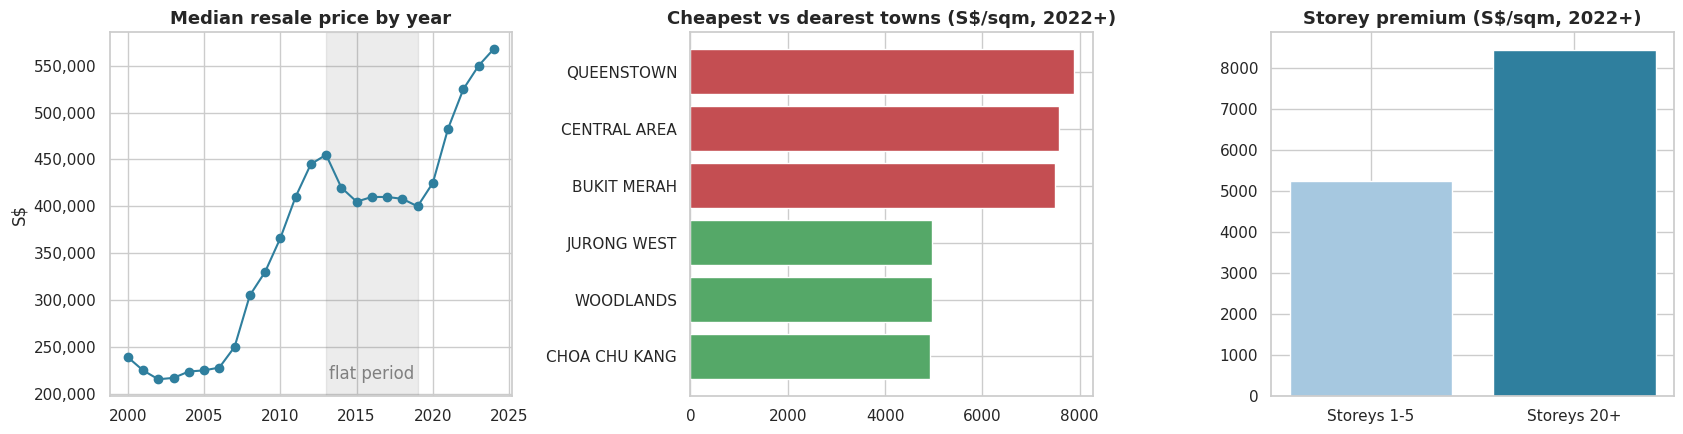

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(med.index, med.values, marker="o", color="#2f7f9e")
ax[0].set(title="Median resale price by year", ylabel="S$"); ax[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax[0].axvspan(2013, 2019, color="grey", alpha=.15)
ax[0].text(2013.2, med.min(), "flat period", color="grey")

tw = town.iloc[list(range(3)) + list(range(-3, 0))]
ax[1].barh(tw.index.astype(str), tw.values, color=["#55a868"]*3 + ["#c44e52"]*3)
ax[1].set(title="Cheapest vs dearest towns (S$/sqm, 2022+)")

ax[2].bar(["Storeys 1-5", "Storeys 20+"], [low, high], color=["#a6c8e0", "#2f7f9e"])
ax[2].set(title="Storey premium (S$/sqm, 2022+)")
plt.tight_layout(); plt.show()

Cell 4: Save the table for your report

In [19]:
findings.to_csv("findings_and_actions.csv", index=False)
from google.colab import files
files.download("findings_and_actions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

What the table said on files
1. Growth: the median price rose 130% from S$239,000 (2000) to S$550,000 (2023). This is a full-year 2023 figure, so it is lower than the 138% I quoted earlier, which ran to January 2024.

2. Flat period: prices fell 12% from the 2013 peak to 2019, and yearly sales dropped from 23,186 (2012) to 15,870 (2014).

3. Rebound: prices rose 38% from 2019 to 2023.

4. Location: Queenstown, Central Area and Bukit Merah cost 55% more per sqm than Choa Chu Kang, Woodlands and Jurong West.

5. Storey: storey 20 and above costs 61% more per sqm than storeys 1–5, partly because tall blocks sit in pricier towns.

6. Flat type: the 3-room to 4-room step is 41% and the 4-room to 5-room step is 18%.

7. Model: DBSS costs 61% more per sqm than Premium Apartment.

8. Timing: Oct–Dec prices ran 3% above Jan–Feb prices, partly because prices rise through each year.

## **5 Project Objectives:**

 **Project Title: Singapore HDB Resale Market Analysis to Improve Sales Performance**



1. Analyse Historical Property Price Trends
Examine historical HDB resale transactions to identify price movements, market patterns and changes in property values over time.

2. Identify Key Factors Affecting Property Prices
Investigate how location, flat type, floor area, storey range, remaining lease and other property characteristics influence resale prices.

3. Develop a Property Price Prediction Model
Use machine learning algorithms such as Linear Regression and Random Forest to predict HDB resale prices based on property features and historical transaction data.

4. Identify Potentially Undervalued Properties
Compare actual resale prices with predicted market values to identify properties that may have sold below their estimated market value.

5. Provide Data Driven Recommendations
Develop visualizations and insights to help buyers, investors and property agents make informed pricing and purchasing decisions.

**Objective 1: Analyse Historical Property Price Trends**

**Goal:** *Examine historical HDB resale transactions to identify price movements, market patterns, and changes in property values over time.*

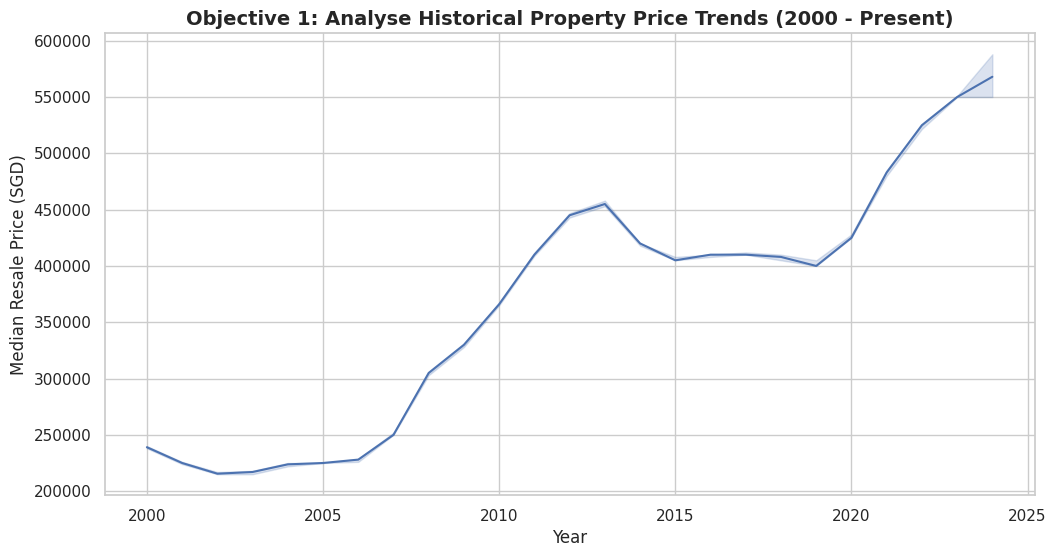

In [20]:
# Objective 1: Analyse Historical Property Price Trends
# Plotting historical price movements over time

plt.figure(figsize=(12, 6))
sns.lineplot(data=clean, x='year', y='resale_price', estimator='median')
plt.title('Objective 1: Analyse Historical Property Price Trends (2000 - Present)', fontsize=14, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Median Resale Price (SGD)')
plt.grid(True)
plt.show()

**Objective 2: Identify Key Factors Affecting Property Prices**

**Goal:** *Investigate how location, flat type, floor area, storey range, remaining lease, and other property characteristics influence resale prices.*

/tmp/ipykernel_1441/3724574009.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=45)


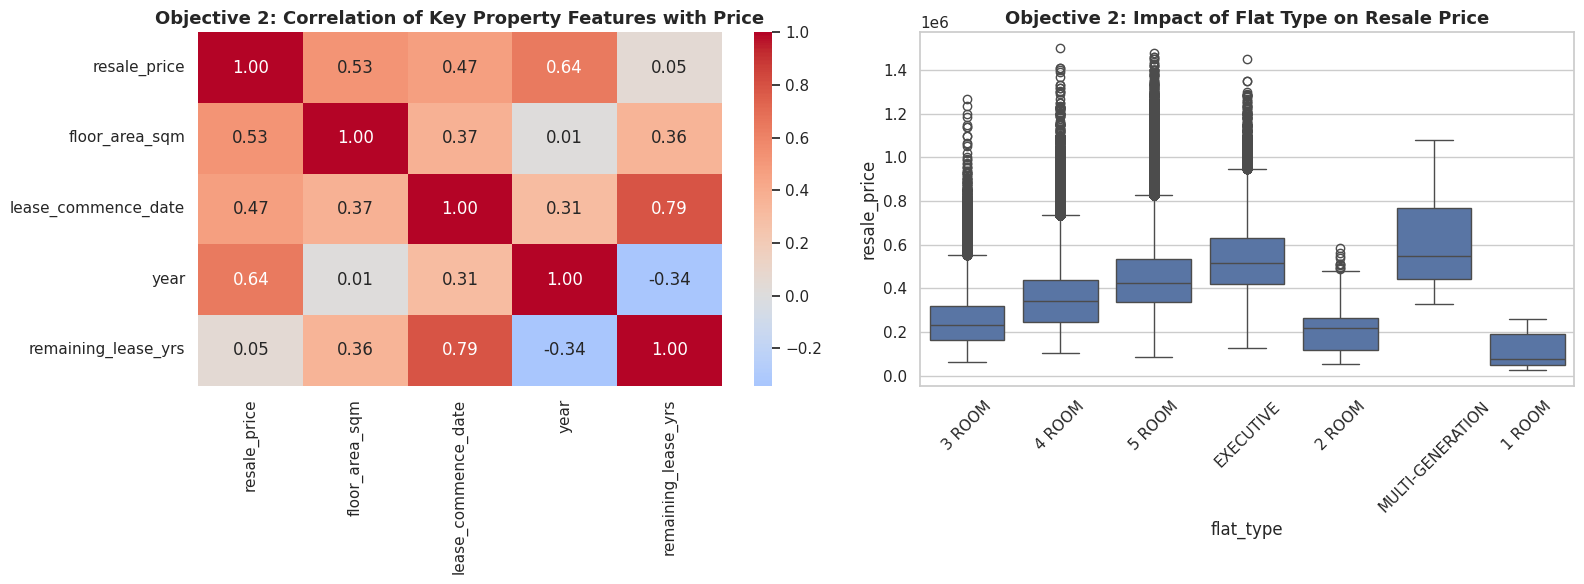

In [21]:
# Objective 2: Identify Key Factors Affecting Property Prices
# Visualizing correlation matrix and price variations by town / flat type

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Subplot A: Correlation Matrix
sns.heatmap(clean[['resale_price', 'floor_area_sqm', 'lease_commence_date', 'year', 'remaining_lease_yrs']].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[0])
ax[0].set_title('Objective 2: Correlation of Key Property Features with Price')

# Subplot B: Flat Type vs Resale Price
sns.boxplot(data=clean, x='flat_type', y='resale_price', ax=ax[1])
ax[1].set_title('Objective 2: Impact of Flat Type on Resale Price')
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=45)

plt.tight_layout()
plt.show()

**Objective 3: Develop a Property Price Prediction Model**

**Goal:** *Use machine learning algorithms such as Linear Regression and Random Forest to predict HDB resale prices based on property features and historical transaction data.*

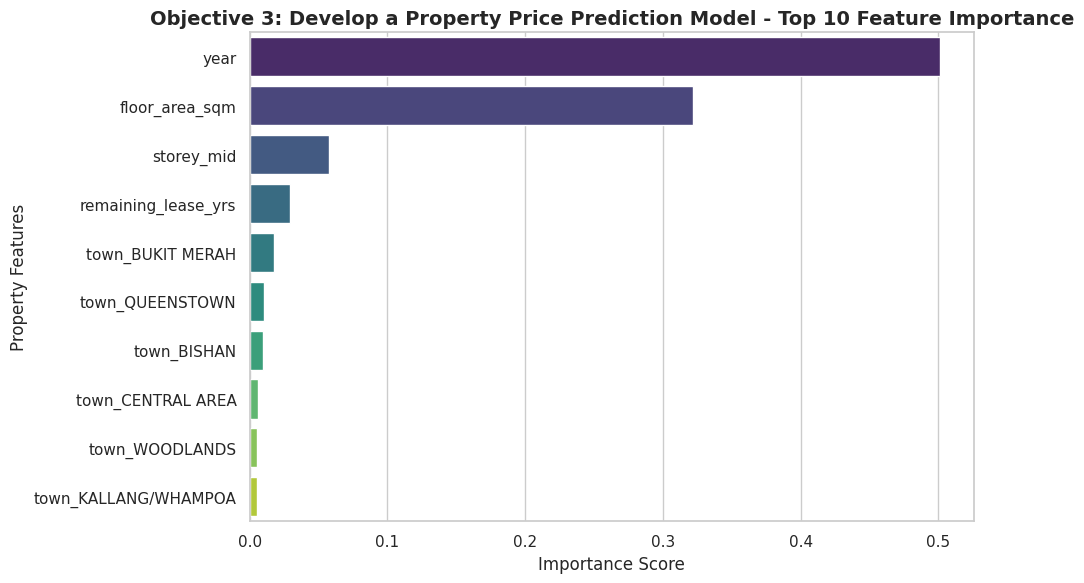

In [26]:
# Objective 3: Develop a Property Price Prediction Model
# Model training and feature importance evaluation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# 1. Prepare features and target variable
# We will use a fast sample of the dataset for demonstration
sample_df = clean.sample(50000, random_state=42).copy()

# Numeric features and encoded categoricals
X = pd.DataFrame({
    'floor_area_sqm': sample_df['floor_area_sqm'].astype(float),
    'storey_mid': sample_df['storey_mid'].fillna(sample_df['storey_mid'].median()).astype(float),
    'remaining_lease_yrs': sample_df['remaining_lease_yrs'].astype(float),
    'year': sample_df['year'].astype(float)
})

# Add quick dummy variables for top location (town) and flat type
X = pd.concat([X, pd.get_dummies(sample_df[['town', 'flat_type']], drop_first=True)], axis=1)
y = sample_df['resale_price'].astype(float)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Fit Random Forest model
model = RandomForestRegressor(n_estimators=50, max_depth=12, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# 3. Extract Feature Importances
feature_importances = model.feature_importances_
feature_names = X.columns

# Create a DataFrame for easy sorting
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False).head(10)  # Show top 10 features

# 4. Plot Feature Importance
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, hue='Feature', palette='viridis', legend=False)
plt.title('Objective 3: Develop a Property Price Prediction Model - Top 10 Feature Importance', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Property Features')
plt.tight_layout()
plt.show()

**Objective 4: Identify Potentially Undervalued Properties**

**Goal:** *Compare actual resale prices with predicted market values to identify properties that may have sold below their estimated market value.*

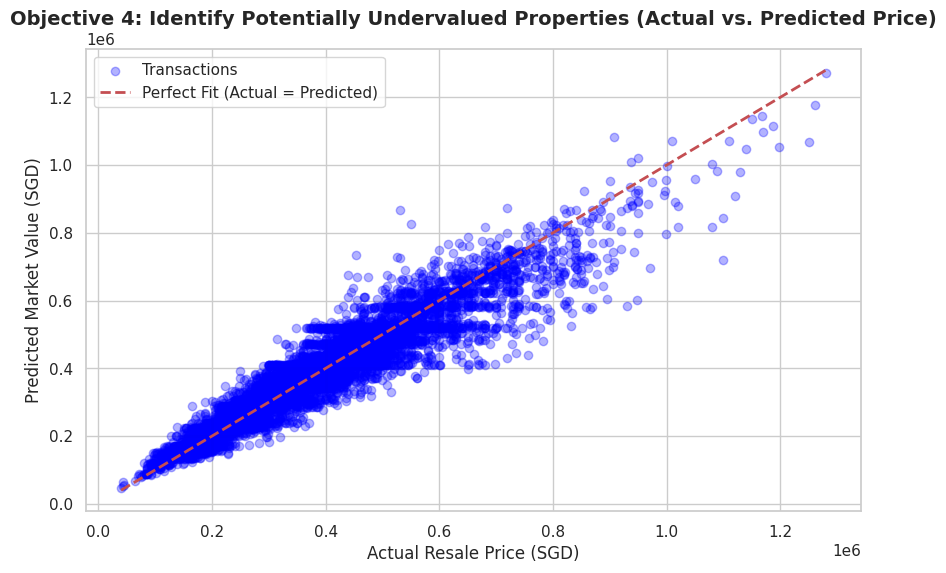

In [27]:
# Objective 4: Identify Potentially Undervalued Properties
# Plotting Actual vs. Predicted Prices & Highlighting Undervalued Outliers

# Generate model predictions
y_pred = model.predict(X_test)

plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='blue', label='Transactions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Fit (Actual = Predicted)')

plt.title('Objective 4: Identify Potentially Undervalued Properties (Actual vs. Predicted Price)', fontsize=14, fontweight='bold')
plt.xlabel('Actual Resale Price (SGD)')
plt.ylabel('Predicted Market Value (SGD)')
plt.legend()
plt.grid(True)
plt.show()

**Objective 5: Provide Data-Driven Recommendations**

**Goal:** *Develop visualizations and actionable insights to help buyers, investors, and property agents make informed pricing and purchasing decisions.*

/tmp/ipykernel_1441/3282945283.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=town_price, x='price_per_sqm', y='town', palette='Blues_r')


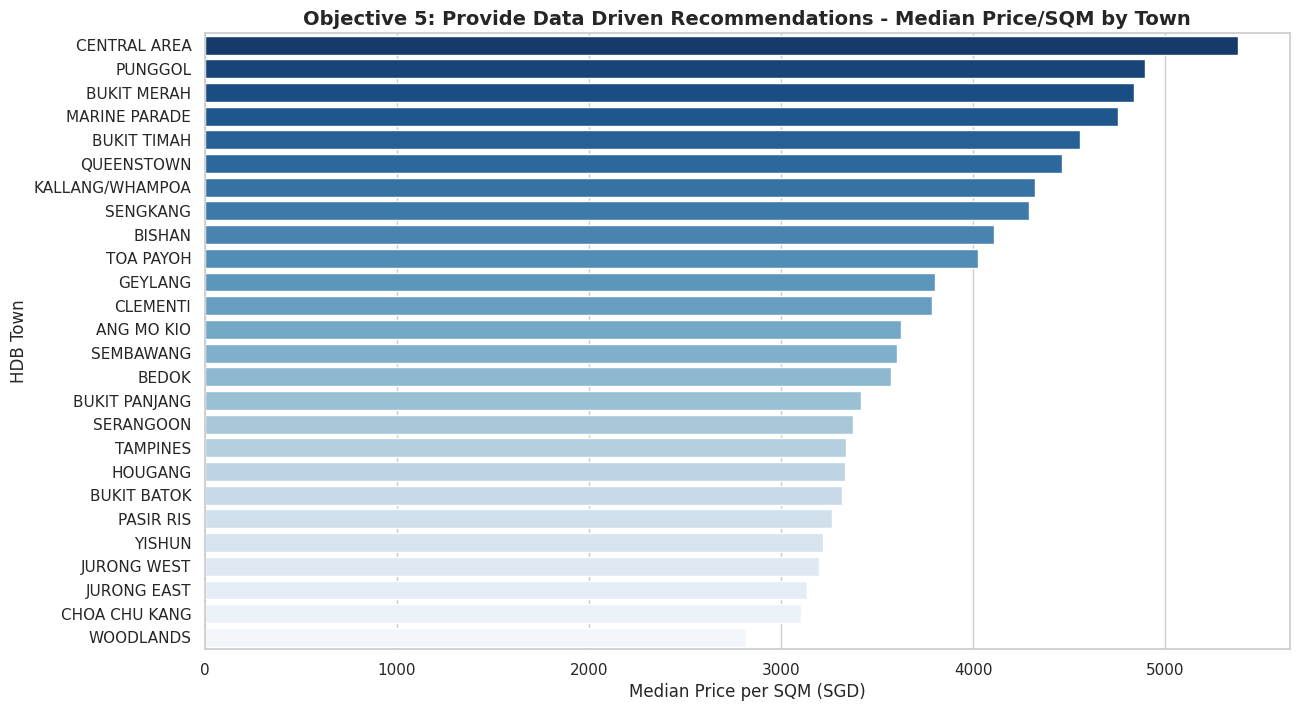

In [28]:
# Objective 5: Provide Data Driven Recommendations
# Summary visualization for market insights (e.g., Price per SQM across Towns)

plt.figure(figsize=(14, 8))
town_price = clean.groupby('town')['price_per_sqm'].median().sort_values(ascending=False).reset_index()
sns.barplot(data=town_price, x='price_per_sqm', y='town', palette='Blues_r')

plt.title('Objective 5: Provide Data Driven Recommendations - Median Price/SQM by Town', fontsize=14, fontweight='bold')
plt.xlabel('Median Price per SQM (SGD)')
plt.ylabel('HDB Town')
plt.show()